# Suicide rates and regional population density: Spain and the United States
### Reproducible figure pipeline for the mini-article

This notebook turns the processed data files into **every figure and every number quoted in the paper**. Nothing is edited by hand: *Run All* regenerates the whole set.

---

## 1. Research question and storyline

> **Are suicide rates associated with how densely populated a region is?**

Population *density* (inhabitants per km²) is the explanatory variable of Figures 1 and 2. Population *size* enters through the cartogram of Figure 2, where the area of each region is proportional to its population. The two views are the same information: **the factor by which a region swells or shrinks in the cartogram is exactly its density relative to the national average** (cartogram area / real area = *k* × density), so the cartogram and the scatter plot show one variable from two angles.

Each main figure has **one message** that can be said in one sentence:

| Paper section | Figure | What the reader can see |
|---|---|---|
| Results 3.1 — The data | **Fig. 1** four maps (population density and suicide rate; United States and Spain; one year) with a histogram under each | How density and suicide rate are distributed over the regions, separately. |
| Results 3.2 — Density and rate | **Fig. 2** area cartograms (area ∝ population, colour = suicide rate) next to the scatter plot rate vs. density | Whether the regions that swell (dense ones) share a colour, and how strong the association is. |
| Results 3.3 — National evolution | **Fig. 3** population and suicide rate, as % change since 2001 | Whether the national suicide rate followed population growth. |
| Results 3.4 — Regional evolution | **Fig. 4** heatmaps (region × year) and regional trajectories (commented) | The regional spread that hides behind the national rate, and how it changed. |
| Supplement | **Fig. S1** funnel plot | Whether regional differences are larger than chance. |

Reproducibility and accessibility are part of the pipeline: section 17 simulates colour-vision deficiencies and greyscale on every main figure.

## 2. Repository layout and how to reproduce

```
your-repo/
├── README.md
├── requirements.txt
├── data/
│   ├── processed/                 <- the four CSV files used by this notebook
│   │   ├── usa_population.csv, usa_suicide_rate.csv, spain_population.csv, spain_suicide_rate.csv
│   └── geo/
│       ├── raw/                   <- (optional) the two official boundary files, see section 8.3
│       ├── spain_nuts2.geojson    <- slim geometry created once by section 8.3, committed to the repo
│       └── us_states.geojson      <- slim geometry created once by section 8.3, committed to the repo
├── notebooks/
│   └── suicide_rates_paper_figures.ipynb      <- this notebook
├── figures/                       <- created automatically (PDF + PNG of every figure)
└── results/                       <- created automatically (CSV with the numbers quoted in the text)
```

1. Clone the repository. 2. `pip install -r requirements.txt`. 3. Open this notebook and choose **Run All**.

**No path depends on your computer.** The notebook looks for the repository root by walking up from its own working directory until it finds the `data/` folder, and builds every path with `pathlib`. Once the two slim geometry files exist in `data/geo/` (they are committed), the notebook needs **no internet** and **no `geopandas`**.

## 3. Data

| File | One row per | Columns used | Source |
|---|---|---|---|
| `usa_suicide_rate.csv` | US state × year | `Year`, `Location`, `Deaths` | CDC (suicide deaths) |
| `usa_population.csv` | US state × year | `year`, `region_name`, `population` | U.S. Census Bureau |
| `spain_suicide_rate.csv` | autonomous community × year | `Periodo`, `Comunidades y Ciudades Autónomas`, `Total` | INE (suicide deaths) |
| `spain_population.csv` | autonomous community × year | `year`, `region_name`, `population` | see the data repository (cite the provider here) |
| `NUTS_RG_03M_2021_4326_LEVL_2.geojson` | NUTS-2 region (Spain) | `NUTS_ID`, geometry | Eurostat GISCO. © EuroGeographics for the administrative boundaries |
| `cb_2018_us_state_5m.zip` | US state | `STUSPS`, geometry | U.S. Census Bureau, cartographic boundary files 2018 (1:5,000,000) |

Coverage: 51 US regions (50 states + DC) and **17 Spanish autonomous communities** (the two autonomous cities, Ceuta and Melilla, are excluded from the analysis, see below), 2001–2021. **Boundaries are joined to the data by region code** (postal code for US states, NUTS-2 code for Spain), never by name.

## 4. Methodological decisions (and why)

- **Always rates, never counts.** A larger region has more suicides only because it has more people, so counts would always rise with population. Every comparison uses *suicides per 100,000 inhabitants* (`suicides / population × 100,000`). Rates are **crude** (no age adjustment): the Spanish data have no age-adjusted series and the US file switches from crude to age-adjusted in 2014.
- **Population density.** `density = population / area`, with the area of each region (km²) measured on its boundary in an equal-area projection. Density is shown on a logarithmic scale because it spans two to three orders of magnitude. The areas come from the *simplified* boundaries used for the maps, so they differ slightly from official land areas.
- **Ceuta and Melilla are excluded (`EXCLUDED_REGIONS`).** They are autonomous *cities* with about 85,000 inhabitants each (0.4 % of the Spanish population together), only a handful of suicides per year (a rate that moves by several points when one case is added or removed), and the highest densities in Spain by far (thousands of inhabitants/km², against about 840 in Madrid), so on a logarithmic density axis they would act as two extreme, very noisy points. They are also enclaves that cannot be drawn as ordinary contiguous regions in the cartogram. Excluding them is therefore a documented analysis choice, applied consistently to rates, maps, cartograms and national totals; it is controlled by one dictionary and **section 18 reports the result with and without them**. For symmetry, the same section reports the United States without DC, the only US region with a comparable density.
- **One year for the maps** (`YEAR = 2021`). Small regions have few suicides in a single year, so their rate is noisy; the year-by-year correlation (section 10.3, summarised in section 18) checks that the chosen year is not special.
- **Equal-area projection.** Maps and cartograms use an Albers equal-area conic projection, so that areas on the page are proportional to areas on the ground. This matters for the cartogram and for the density.
- **Cartogram.** Contiguous area cartogram (Dougenik–Chrisman–Niemeyer rubber-sheet algorithm, implemented here with `numpy`): every region is deformed until its area is proportional to its population, keeping neighbours in contact. Insets and enclaves (Alaska, Hawaii, DC, Canary Islands) are rescaled in place to the same area per inhabitant, because a rubber sheet cannot stretch them realistically.
- **Association.** Spearman rank correlation ρ (robust to very different region sizes) with a bootstrap 95 % interval, and a least-squares line of the rate on log₁₀(density) with its R². Both are *descriptive and ecological*, not causal. The same statistics for population *size* are reported in section 18.
- **Colour.** One central palette (section 7.1) used by every figure: four colour identities (population/density and suicide rate, for each country) plus the colours of the relationship figure. Sequential colormaps are used for quantities; line styles and markers also distinguish the series, so that figures can be read in greyscale. Section 17 tests it.
- **Randomness.** Only the bootstrap uses random numbers; its seed is fixed.

## 5. How to read this notebook

Every code cell is preceded by a markdown cell that says **what it does and why**.

## 6. Setup

### 6.1 Imports, library versions and switches

*What it does.* Imports the libraries (only `numpy`, `pandas`, `matplotlib` and `scipy` are needed to run the figures; `geopandas` is needed **only once**, in section 8.3), prints their versions and defines the switches of the run.

- `SAVE_FIGURES`: write every figure as vector PDF (editable text) and 300-dpi PNG into `figures/`.
- `YEAR`: the single year shown in the maps, the cartograms and the funnel plot.
- `N_BOOT`, `SEED`: bootstrap resamples and random seed (fixed, so results are identical on every run).

In [1]:
import sys, json, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import Normalize, LogNorm
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Rectangle
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullLocator, MaxNLocator
from scipy.stats import spearmanr, rankdata

# ----- switches -----
SAVE_FIGURES = True            # write PDF + PNG of every figure into <repo>/figures
YEAR = 2021                    # single year shown in Figs. 1, 2 and S1
N_BOOT, SEED = 5000, 2024      # bootstrap resamples and random seed

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {mpl.__version__} | scipy {scipy.__version__}")

# # ----- switches -----
# SAVE_FIGURES = True
# YEAR = 2021
# N_BOOT, SEED = 5000, 2024

# # ----- scope -----
# COUNTRIES = ["United States", "Spain"]   # países analizados; usado por todo el notebook
# FULL_W = 7.1                              # ancho de figura a página completa (in)

Python 3.12.16 | numpy 2.5.4 | pandas 3.1.0 | matplotlib 3.11.2 | scipy 1.18.1


### 6.2 Paths (the reproducibility core)

*What it does.* Finds the repository root and defines every input/output path with `pathlib`, so no absolute path is ever written in the code.

1. Starting from the notebook's working directory, it walks **up** the folder tree until it finds a folder named `data` (or `datos`). That folder's parent is the repository root.
2. `DATA_DIR`, `GEO_DIR`, `FIG_DIR` and `RESULTS_DIR` are derived from the root. Output folders are created if missing.
3. The four input tables are read from `data/processed/`. The cell checks that they exist and stops with a clear message if one is missing.

If you launch Jupyter from an unrelated folder, set `REPO_ROOT_OVERRIDE = Path("...")` once; otherwise leave it as `None`.

In [2]:
REPO_ROOT_OVERRIDE = None                 # e.g. Path("/path/to/your-repo") if Jupyter is started elsewhere
DATA_FOLDER_NAMES = ("data", "datos")     # accepted names of the data folder

def find_repo_root(start=None):
    # Walk up from `start` (default: current working directory) until a data folder is found
    start = Path(start or Path.cwd()).resolve()
    for folder in [start, *start.parents]:
        for name in DATA_FOLDER_NAMES:
            if (folder / name).is_dir():
                return folder, folder / name
    raise FileNotFoundError(
        f"No '{'/'.join(DATA_FOLDER_NAMES)}' folder found in {start} or any parent folder. "
        "Open the notebook from inside the repository or set REPO_ROOT_OVERRIDE.")

if REPO_ROOT_OVERRIDE is not None:
    REPO_ROOT = Path(REPO_ROOT_OVERRIDE).resolve()
    DATA_DIR = next(REPO_ROOT / n for n in DATA_FOLDER_NAMES if (REPO_ROOT / n).is_dir())
else:
    REPO_ROOT, DATA_DIR = find_repo_root()

GEO_DIR = DATA_DIR / "geo"
FIG_DIR, RESULTS_DIR = REPO_ROOT / "figures", REPO_ROOT / "results"
GEO_DIR.mkdir(exist_ok=True); (GEO_DIR / "raw").mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True); RESULTS_DIR.mkdir(exist_ok=True)

FILES = {
    "usa_pop": DATA_DIR / "processed" / "usa_population.csv",
    "usa_sui": DATA_DIR / "processed" / "usa_suicide_rate.csv",
    "esp_pop": DATA_DIR / "processed" / "spain_population.csv",
    "esp_sui": DATA_DIR / "processed" / "spain_suicide_rate.csv",
}
missing = [p.name for p in FILES.values() if not p.exists()]
assert not missing, f"Missing input files in {DATA_DIR}: {missing}"
print("Repository root:", REPO_ROOT.name, "| data folder:", DATA_DIR.name, "| all input files found")

Repository root: Data-analysis-mental-health-and-weather | data folder: data | all input files found


## 7. Visual identity and plotting helpers

### 7.1 Central palette (one place to change every colour)

*What it does.* Defines **all the colours of the notebook in one cell**. To recolour a figure, change the dictionaries here; no figure code has to be edited.

There are four dictionaries, each with a clear job:

| Dictionary | Key | Used for | Where |
|---|---|---|---|
| `CMAP_SERIES` | (country, variable) | **sequential colormaps** of each series: pink = US density, blue = US suicide rate, orange = Spain density, green = Spain suicide rate | maps and histograms of Fig. 1, heatmaps of Fig. 4 |
| `COLOR_SERIES` | (country, variable) | **flat line colours** of the same four series | Fig. 3 (lines, end labels and legend) |
| `CMAP_BOTH` | country | colour scale of the **suicide rate in the relationship figure** (darker = higher rate): purple for the US, reversed copper for Spain | cartograms and scatter dots of Fig. 2 |
| `RELATIONSHIP_COLOR` | country | **flat colours** that match `CMAP_BOTH` | regional trajectories of Fig. 4 and funnel plot S1 |

The variable `"density"` stands for everything related to population size: population density in Figs. 1, and the population line in Fig. 3. Markers (circle: US, square: Spain) and line styles (dashed: population, solid: suicide rate) carry the same information as colour.

Typography is sized for the printed page: 8 pt text, 7.5 pt ticks; fonts are embedded as editable text in the PDFs.

In [3]:
FULL_W = 7.1    # width of a full-page-width figure, in inches (final printed size)
COUNTRIES = ["United States", "Spain"]

# ---------------------------------------
# CENTRAL COLOUR PALETTE
# ---------------------------------------
# Sequential colormaps of each series (maps, histograms, heatmaps)
CMAP_SERIES = {
    ("United States", "density"): "RdPu",
    ("United States", "rate"): "Blues",

    ("Spain", "density"): "YlOrBr",
    ("Spain", "rate"): "Greens",
}

# Flat colours of the same series (lines)
COLOR_SERIES = {
    ("United States", "density"): "#ed549d",
    ("United States", "rate"): "#5ba3d0",

    ("Spain", "density"): "#feaa38",
    ("Spain", "rate"): "#3ba458",
}

# Colour scale of the suicide rate in the relationship figure (Fig. 2): darker = higher rate
CMAP_BOTH = {
    "United States": "Purples",
    "Spain": "copper_r",
}

# Flat colours that match CMAP_BOTH (trajectories, funnel plot)
RELATIONSHIP_COLOR = {
    "United States": "#9A5B9A",
    "Spain": "#A9824D",
}

COUNTRY_MARKER = {"United States": "o", "Spain": "s"}      # second visual code besides colour
INK, MUTED, LIGHT = "#1F2933", "#66727F", "#DDE3E8"        # text, secondary text, light grey

mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 9, "axes.labelsize": 8, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": LIGHT, "axes.linewidth": 0.7,
    "lines.linewidth": 1.6, "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "figure.dpi": 130, "savefig.dpi": 300,
    "pdf.fonttype": 42, "ps.fonttype": 42,          # embed fonts as editable text
})


In [4]:
# FULL_W = 7.1
# COUNTRIES = ["United States", "Spain"]

# # ---------------------------------------
# # CENTRAL COLOUR PALETTE  —  Option A
# # ---------------------------------------
# # Color encodes the VARIABLE (density vs rate), shape/style encodes the COUNTRY.
# # Only two hue families: blue (density) and orange (rate).
# # Within each family, US = lighter, ES = darker (luminance step, not hue step).

# CMAP_SERIES = {
#     ("United States", "density"): "Blues",
#     ("Spain",         "density"): "Blues",
#     ("United States", "rate"):    "Oranges",
#     ("Spain",         "rate"):    "Oranges",
# }

# COLOR_SERIES = {
#     ("United States", "density"): "#6BAED6",   # blue, light
#     ("Spain",         "density"): "#08519C",   # blue, dark
#     ("United States", "rate"):    "#FD8D3C",   # orange, light
#     ("Spain",         "rate"):    "#A63603",   # orange, dark
# }

# # Figure 2: single monotonic-in-luminance scale (safe for deuteranopia)
# CMAP_BOTH = {
#     "United States": "cividis",
#     "Spain":         "cividis",
# }
# # 
# # Flat colours matching cividis endpoints (dark end for US, warm end for ES)
# RELATIONSHIP_COLOR = {
#     "United States": "#00224E",   # cividis dark blue
#     "Spain":         "#FDE725",   # cividis yellow  (use darker text if on light bg)
# }

# COUNTRY_MARKER = {"United States": "o", "Spain": "s"}   # circle vs square
# COUNTRY_LINESTYLE = {"United States": "-", "Spain": "--"}  # solid vs dashed (extra channel)

# INK, MUTED, LIGHT = "#1F2933", "#66727F", "#DDE3E8"

In [5]:
# ---------------------------------------
# CENTRAL COLOUR PALETTE  —  Option B
# ---------------------------------------
# Country = hue family (US = blue, ES = orange). Variable = luminance step.
# This keeps the "four identities" idea without red/green or purple/blue pairs.

# CMAP_SERIES = {
#     # US: blue family. Density = lighter end, rate = darker end.
#     ("United States", "density"): "Blues",
#     ("United States", "rate"):    "Blues",
#     # ES: orange family. Density = lighter end, rate = darker end.
#     ("Spain",         "density"): "Oranges",
#     ("Spain",         "rate"):    "Oranges",
# }

# COLOR_SERIES = {
#     ("United States", "density"): "#9ECAE1",   # blue light
#     ("United States", "rate"):    "#08519C",   # blue dark
#     ("Spain",         "density"): "#FDD0A2",   # orange light
#     ("Spain",         "rate"):    "#A63603",   # orange dark
# }

# CMAP_BOTH = {
#     "United States": "cividis",
#     "Spain":         "cividis",
# }

# RELATIONSHIP_COLOR = {
#     "United States": "#00224E",
#     "Spain":         "#A6761D",   # darker cividis yellow, safe for lines
# }

# COUNTRY_MARKER = {"United States": "o", "Spain": "s"}
# COUNTRY_LINESTYLE = {"United States": "-", "Spain": "--"}

# INK, MUTED, LIGHT = "#1F2933", "#66727F", "#DDE3E8"

### 7.2 Generic helpers

*What it does.* Small functions reused by several figures:

- `clean_axes` applies the minimal editorial style (no top/right spines, light grid on one axis).
- `pop_formatter` writes large numbers as `100`, `1k`, `1M` (used on the density axes of the histograms).
- `FIGS` keeps every main figure so that section 17 can test it for colour-vision deficiencies, and `save_figure` writes PDF + PNG into `figures/` when `SAVE_FIGURES` is on.

In [6]:
def clean_axes(ax, grid="y", left=True):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.spines["left"].set_color(LIGHT); ax.spines["bottom"].set_color(LIGHT)
    ax.spines["left"].set_visible(left)
    ax.tick_params(length=0, pad=3)
    ax.set_axisbelow(True); ax.grid(False)
    if grid in ("y", "both"): ax.grid(axis="y", color=LIGHT, lw=0.5, alpha=0.9)
    if grid in ("x", "both"): ax.grid(axis="x", color=LIGHT, lw=0.5, alpha=0.9)

def pop_formatter(v, _):
    if v >= 1_000_000: return f"{v/1_000_000:g}M"
    if v >= 1_000: return f"{v/1_000:g}k"
    return f"{v:g}"

FIGS = {}
def save_figure(fig, name):
    FIGS[name] = fig
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", pad_inches=0.03)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
        print(f"saved: {(FIG_DIR / name).relative_to(REPO_ROOT)}.pdf / .png")

## 8. Data

### 8.1 Load, harmonise and compute rates

*What it does.*
1. Reads the four CSV files of `data/processed/` with the paths built above.
2. Gives US and Spanish data **the same four columns** (`year`, `region`, `suicides`, `population`).
3. Harmonises Spanish region names (the two Spanish files spell some communities differently, and the suicide file carries a numeric prefix like `01 Andalucía`).
4. Joins suicides and population with `validate="1:1"`, so pandas raises an error if any region-year is duplicated or ambiguous.
5. Computes `rate = suicides / population × 100,000` (crude suicide rate).
6. Runs **sanity checks** on the complete data (expected number of regions, complete region-year grid, no missing values, no negative counts). If the data change, these checks fail loudly instead of silently producing wrong figures.

The result is `PANELS_ALL`: all regions, including the two Spanish autonomous cities. The analysis scope is chosen in section 9.3.

In [7]:
PopUSA = pd.read_csv(FILES["usa_pop"])      # population by state and year
SuiUSA = pd.read_csv(FILES["usa_sui"])      # suicide deaths by state and year
PopESP = pd.read_csv(FILES["esp_pop"])      # population by autonomous community and year
SuiESP = pd.read_csv(FILES["esp_sui"])      # suicide deaths by autonomous community and year

ESP_NAMES = {                                # Spanish names that differ between the two files
    "03 Asturias, Principado de": "Principado de Asturias", "04 Balears, Illes": "Illes Balears",
    "08 Castilla - La Mancha": "Castilla-La Mancha", "13 Madrid, Comunidad de": "Comunidad de Madrid",
    "14 Murcia, Región de": "Región de Murcia", "15 Navarra, Comunidad Foral de": "Comunidad Foral de Navarra",
    "17 Rioja, La": "La Rioja", "18 Ceuta": "Ciudad de Ceuta", "19 Melilla": "Ciudad de Melilla",
}
esp_name = lambda s: ESP_NAMES.get(s, s[3:])         # all others only lose the "01 " prefix

usa = (SuiUSA.rename(columns={"Year": "year", "Location": "region", "Deaths": "suicides"})[["year", "region", "suicides"]]
       .merge(PopUSA.rename(columns={"region_name": "region"})[["year", "region", "population"]],
              on=["year", "region"], validate="1:1"))
esp = (SuiESP.rename(columns={"Periodo": "year", "Total": "suicides"})
       .assign(region=lambda t: t["Comunidades y Ciudades Autónomas"].map(esp_name))[["year", "region", "suicides"]]
       .merge(PopESP.rename(columns={"region_name": "region"})[["year", "region", "population"]],
              on=["year", "region"], validate="1:1"))

PANELS_ALL = {"United States": usa, "Spain": esp}
EXPECTED_REGIONS_ALL = {"United States": 51, "Spain": 19}
for name, p in PANELS_ALL.items():
    p["rate"] = p["suicides"] / p["population"] * 100_000            # suicides per 100,000 inhabitants
    assert p["region"].nunique() == EXPECTED_REGIONS_ALL[name], f"{name}: unexpected number of regions"
    assert len(p) == EXPECTED_REGIONS_ALL[name] * p["year"].nunique(), f"{name}: incomplete region-year grid"
    assert p[["suicides", "population"]].notna().all().all() and (p["suicides"] >= 0).all(), f"{name}: bad values"
    print(f"{name:14s} {p['region'].nunique()} regions x {p['year'].nunique()} years = {len(p)} rows "
          f"({p['year'].min()}-{p['year'].max()})")
assert YEAR in set(usa["year"]) and YEAR in set(esp["year"]), "YEAR is not in the data"

United States  51 regions x 21 years = 1071 rows (2001-2021)
Spain          19 regions x 21 years = 399 rows (2001-2021)


### 8.2 Region codes (the join keys)

*What it does.* Defines the **code of every region**: the US postal abbreviation (`STUSPS` in the Census files) and the Spanish NUTS-2 code (`NUTS_ID` in the Eurostat file). Boundaries are joined to the data through these codes, never through names. Two assertions check that every region of the data has exactly one code and that no code is repeated. `REGION_CODE_ALL` contains all regions; the regions actually analysed are selected in section 9.3.

In [8]:
US_ABBR = {
    "Alabama":"AL","Alaska":"AK","Arizona":"AZ","Arkansas":"AR","California":"CA","Colorado":"CO","Connecticut":"CT",
    "Delaware":"DE","District of Columbia":"DC","Florida":"FL","Georgia":"GA","Hawaii":"HI","Idaho":"ID","Illinois":"IL",
    "Indiana":"IN","Iowa":"IA","Kansas":"KS","Kentucky":"KY","Louisiana":"LA","Maine":"ME","Maryland":"MD",
    "Massachusetts":"MA","Michigan":"MI","Minnesota":"MN","Mississippi":"MS","Missouri":"MO","Montana":"MT",
    "Nebraska":"NE","Nevada":"NV","New Hampshire":"NH","New Jersey":"NJ","New Mexico":"NM","New York":"NY",
    "North Carolina":"NC","North Dakota":"ND","Ohio":"OH","Oklahoma":"OK","Oregon":"OR","Pennsylvania":"PA",
    "Rhode Island":"RI","South Carolina":"SC","South Dakota":"SD","Tennessee":"TN","Texas":"TX","Utah":"UT",
    "Vermont":"VT","Virginia":"VA","Washington":"WA","West Virginia":"WV","Wisconsin":"WI","Wyoming":"WY",
}
ESP_NUTS2 = {
    "Galicia":"ES11", "Principado de Asturias":"ES12", "Cantabria":"ES13", "País Vasco":"ES21",
    "Comunidad Foral de Navarra":"ES22", "La Rioja":"ES23", "Aragón":"ES24", "Comunidad de Madrid":"ES30",
    "Castilla y León":"ES41", "Castilla-La Mancha":"ES42", "Extremadura":"ES43", "Cataluña":"ES51",
    "Comunitat Valenciana":"ES52", "Illes Balears":"ES53", "Andalucía":"ES61", "Región de Murcia":"ES62",
    "Ciudad de Ceuta":"ES63", "Ciudad de Melilla":"ES64", "Canarias":"ES70",
}
REGION_CODE_ALL = {"United States": US_ABBR, "Spain": ESP_NUTS2}
for c in COUNTRIES:
    assert set(REGION_CODE_ALL[c]) == set(PANELS_ALL[c]["region"].unique()), f"{c}: region names and codes do not match"
    assert len(set(REGION_CODE_ALL[c].values())) == len(REGION_CODE_ALL[c]), f"{c}: duplicated codes"
print("Region codes OK:", {c: len(v) for c, v in REGION_CODE_ALL.items()})

Region codes OK: {'United States': 51, 'Spain': 19}


### 8.3 Boundary files: one-time preparation (needs internet and `geopandas`, only the first time)

*What it does.* The maps need polygon boundaries. To keep the repository small and the notebook **independent of the internet and of `geopandas`**, this cell converts the two official boundary files into two **slim GeoJSON files** (only the 19 Spanish NUTS-2 regions and the 51 US regions, simplified, with just a `code` and a `name`) saved in `data/geo/`. **Commit those two files to the repository**: afterwards the cell finds them and does nothing.

If the slim files are missing, the cell:
1. looks for the raw files in `data/geo/raw/` (you can simply copy them there) and otherwise downloads them: Eurostat GISCO `NUTS_RG_03M_2021_4326_LEVL_2.geojson` (Spain, NUTS level 2) and Census `cb_2018_us_state_5m.zip`;
2. filters the Spanish NUTS-2 regions and the 50 states + DC, **by code**;
3. simplifies each outline (tolerance of about 1–2 km), drops specks smaller than a few hundred km², and writes `spain_nuts2.geojson` and `us_states.geojson`.

Simplification keeps the figure readable and the cartogram fast; it does not alter the data (the areas used for the density come from these simplified outlines, see section 4).

In [9]:
SPAIN_RAW = GEO_DIR / "raw" / "NUTS_RG_03M_2021_4326_LEVL_2.geojson"
US_RAW = GEO_DIR / "raw" / "cb_2018_us_state_5m.zip"
SPAIN_URL = "https://gisco-services.ec.europa.eu/distribution/v2/nuts/geojson/NUTS_RG_03M_2021_4326_LEVL_2.geojson"
US_URL = "https://www2.census.gov/geo/tiger/GENZ2018/shp/cb_2018_us_state_5m.zip"
SPAIN_SLIM, US_SLIM = GEO_DIR / "spain_nuts2.geojson", GEO_DIR / "us_states.geojson"

def _ensure_raw(path, url):
    if not path.exists():
        print(f"downloading {url}")
        urllib.request.urlretrieve(url, path)

def prepare_geometries():
    if SPAIN_SLIM.exists() and US_SLIM.exists():
        print("Slim geometry files found in", GEO_DIR.relative_to(REPO_ROOT), "- nothing to do.")
        return
    import geopandas as gpd                      # only needed here, only the first time
    from shapely.geometry import MultiPolygon

    def slim(gdf, code_col, name_col, keep_codes, tol, min_area):
        gdf = gdf[gdf[code_col].isin(keep_codes)].to_crs(4326)
        rows = []
        for _, r in gdf.iterrows():
            geom = r.geometry.simplify(tol, preserve_topology=True)
            parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
            big = [p for p in parts if p.area >= min_area] or [max(parts, key=lambda p: p.area)]
            rows.append({"code": r[code_col], "name": r[name_col], "geometry": MultiPolygon(big)})
        out = gpd.GeoDataFrame(rows, geometry="geometry", crs="EPSG:4326")
        assert set(out["code"]) == set(keep_codes), f"missing regions: {set(keep_codes) - set(out['code'])}"
        return out

    if not SPAIN_SLIM.exists():
        _ensure_raw(SPAIN_RAW, SPAIN_URL)
        g = gpd.read_file(SPAIN_RAW)
        g = g[(g["LEVL_CODE"] == 2) & (g["CNTR_CODE"] == "ES")]
        name_col = "NAME_LATN" if "NAME_LATN" in g.columns else "NUTS_NAME"
        slim(g, "NUTS_ID", name_col, set(ESP_NUTS2.values()), 0.01, 0.004).to_file(SPAIN_SLIM, driver="GeoJSON")
    if not US_SLIM.exists():
        _ensure_raw(US_RAW, US_URL)
        try:
            g = gpd.read_file(US_RAW)
        except Exception:
            g = gpd.read_file("zip://" + US_RAW.as_posix())
        slim(g, "STUSPS", "NAME", set(US_ABBR.values()), 0.02, 0.01).to_file(US_SLIM, driver="GeoJSON")
    print("Created:", SPAIN_SLIM.name, "and", US_SLIM.name, "in", GEO_DIR.relative_to(REPO_ROOT), "- commit them to the repository.")

prepare_geometries()

Slim geometry files found in data\geo - nothing to do.


### 8.4 Read the slim geometries (no `geopandas` needed)

*What it does.* Reads the two slim GeoJSON files with the standard `json` module. Every region becomes a list of polygons; every polygon is a list of rings (the outer ring first, then holes), and every ring a `numpy` array of longitude/latitude. The result, `GEO_ALL`, holds **all** regions of the files; a check confirms that the boundary files and the data contain exactly the same regions (join by code).

In [10]:
def read_slim_geojson(path):
    gj = json.loads(Path(path).read_text(encoding="utf-8"))
    out = {}
    for f in gj["features"]:
        g = f["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        out[f["properties"]["code"]] = [[np.asarray(r, dtype=float)[:, :2] for r in poly] for poly in polys]
    return out

GEO_ALL = {"United States": read_slim_geojson(US_SLIM), "Spain": read_slim_geojson(SPAIN_SLIM)}
for c in COUNTRIES:
    assert set(GEO_ALL[c]) == set(REGION_CODE_ALL[c].values()), f"{c}: boundary codes do not match the data codes"
print("Geometry OK:", {c: len(v) for c, v in GEO_ALL.items()})

Geometry OK: {'United States': 51, 'Spain': 19}


## 9. Map geometry, derived variables and cartogram

### 9.1 Geometry helpers and equal-area projection

*What it does.* Small geometry tools written with `numpy` (so the notebook needs no GIS library):

- `albers`: **Albers equal-area conic projection** (spherical form). Equal area is essential: the density and the cartogram are based on areas. Longitudes are wrapped around the projection centre, so Alaska's Aleutian Islands, which cross the 180° meridian, stay in one piece.
- ring/polygon tools: signed area, centroid, bounding box and orientation (outer rings counter-clockwise, holes clockwise, so that holes are drawn as holes).
- one projection per group of regions: the contiguous states (+ DC), Alaska and Hawaii; peninsular Spain (+ Balearic Islands and, if included, Ceuta and Melilla) and the Canary Islands.

In [11]:
R_EARTH = 6371.0088   # km

def albers(lon, lat, lon0, lat0, lat1, lat2):
    # Spherical Albers equal-area conic projection; returns x, y in km
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    p, p0, p1, p2 = (np.radians(v) for v in (lat, lat0, lat1, lat2))
    n = (np.sin(p1) + np.sin(p2)) / 2
    C = np.cos(p1) ** 2 + 2 * n * np.sin(p1)
    rho = R_EARTH * np.sqrt(np.maximum(C - 2 * n * np.sin(p), 0)) / n
    rho0 = R_EARTH * np.sqrt(C - 2 * n * np.sin(p0)) / n
    theta = n * np.radians((lon - lon0 + 180.0) % 360.0 - 180.0)        # wrap longitude around the centre
    return rho * np.sin(theta), rho0 - rho * np.cos(theta)

PROJ = {
    "US_MAIN": dict(lon0=-96, lat0=37.5, lat1=29.5, lat2=45.5),
    "US_AK": dict(lon0=-154, lat0=50, lat1=55, lat2=65),
    "US_HI": dict(lon0=-157, lat0=3, lat1=8, lat2=18),
    "ES_MAIN": dict(lon0=-3, lat0=40, lat1=36, lat2=43),
    "ES_CAN": dict(lon0=-16, lat0=28, lat1=27, lat2=29),
}
# projection used by each non-default region; everything else uses the main projection
REGION_PROJ = {"United States": {"AK": "US_AK", "HI": "US_HI"}, "Spain": {"ES70": "ES_CAN"}}
MAIN_PROJ = {"United States": "US_MAIN", "Spain": "ES_MAIN"}

def ring_area(r):
    x, y = r[:, 0], r[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

def orient(geom):
    # outer ring counter-clockwise (area > 0), holes clockwise
    out = []
    for poly in geom:
        rings = []
        for k, r in enumerate(poly):
            a = ring_area(r)
            rings.append(r[::-1].copy() if (a < 0) == (k == 0) else r)
        out.append(rings)
    return out

def geom_area(geom):
    return sum(ring_area(poly[0]) + sum(ring_area(h) for h in poly[1:]) for poly in geom)    # holes have negative area

def geom_centroid(geom):
    mx = my = a_tot = 0.0
    for poly in geom:
        r = poly[0]; x, y = r[:, 0], r[:, 1]
        cr = x * np.roll(y, -1) - np.roll(x, -1) * y
        mx += np.sum((x + np.roll(x, -1)) * cr) / 6; my += np.sum((y + np.roll(y, -1)) * cr) / 6; a_tot += 0.5 * cr.sum()
    return np.array([mx / a_tot, my / a_tot])

def anchor_point(geom):
    # centroid of the largest polygon: a good spot to put a number on a region
    return geom_centroid([max(geom, key=lambda poly: ring_area(poly[0]))])

def geom_bbox(geoms):
    pts = np.vstack([r for g in geoms.values() for poly in g for r in poly[:1]])
    return pts[:, 0].min(), pts[:, 0].max(), pts[:, 1].min(), pts[:, 1].max()

def map_geom(geom, fn):
    return [[fn(r) for r in poly] for poly in geom]

def project_geom(geom, proj):
    return orient(map_geom(geom, lambda r: np.column_stack(albers(r[:, 0], r[:, 1], **PROJ[proj]))))

def scale_geom(geom, factor, about=None):
    c = geom_centroid(geom) if about is None else np.asarray(about)
    return map_geom(geom, lambda r: c + (r - c) * factor)

def shift_geom(geom, dx, dy):
    return map_geom(geom, lambda r: r + np.array([dx, dy]))

### 9.2 Region areas and population density

*What it does.* Measures the **area (km²) of every region** on its boundary in the equal-area projection (`AREA_KM2`) and adds two columns to `PANELS_ALL`: `area_km2` and `density = population / area_km2` (inhabitants per km²). Areas are computed for **all** regions, including the ones that may be excluded in section 9.3, so that the sensitivity analysis of section 18 can use them. The areas come from the simplified outlines of section 8.3, so they are close to, but not exactly, the official land areas.

In [12]:
def region_areas_km2(country):
    # Area of every region (km2), measured on its boundary in the equal-area projection
    return {code: abs(geom_area(project_geom(g, REGION_PROJ[country].get(code, MAIN_PROJ[country]))))
            for code, g in GEO_ALL[country].items()}

AREA_KM2 = {c: region_areas_km2(c) for c in COUNTRIES}
for c in COUNTRIES:
    area_by_region = {region: AREA_KM2[c][code] for region, code in REGION_CODE_ALL[c].items()}
    PANELS_ALL[c]["area_km2"] = PANELS_ALL[c]["region"].map(area_by_region)
    PANELS_ALL[c]["density"] = PANELS_ALL[c]["population"] / PANELS_ALL[c]["area_km2"]       # inhabitants per km2
    assert PANELS_ALL[c]["density"].notna().all(), f"{c}: some region has no area"

### 9.3 Analysis scope: regions that are excluded

*What it does.* Applies, **in one place**, the decision of which regions are analysed. `EXCLUDED_REGIONS` lists them: by default the two Spanish autonomous cities, **Ceuta and Melilla** (the reasons are in section 4: tiny populations, a handful of suicides per year, extreme densities, enclave geography). From this dictionary the cell derives everything the rest of the notebook uses:

- `PANELS`: the data of the analysed regions only;
- `REGION_CODE`: their codes;
- `GEO_LONLAT`: their boundaries.

Then it checks that data, codes and boundaries describe exactly the same regions and reports how much of the population is left out. To include Ceuta and Melilla again, set `EXCLUDED_REGIONS["Spain"] = []` and run everything again. Section 18 reports the main correlation with and without them.

In [13]:
EXCLUDED_REGIONS = {
    "United States": [],
    "Spain": ["Ciudad de Ceuta", "Ciudad de Melilla"],      # autonomous cities: see section 4
}

PANELS = {c: PANELS_ALL[c][~PANELS_ALL[c]["region"].isin(EXCLUDED_REGIONS[c])].copy() for c in COUNTRIES}
REGION_CODE = {c: {r: code for r, code in REGION_CODE_ALL[c].items() if r not in EXCLUDED_REGIONS[c]} for c in COUNTRIES}
GEO_LONLAT = {c: {code: g for code, g in GEO_ALL[c].items() if code in set(REGION_CODE[c].values())} for c in COUNTRIES}

for c in COUNTRIES:
    assert set(PANELS[c]["region"]) == set(REGION_CODE[c]), f"{c}: data and codes differ"
    assert set(GEO_LONLAT[c]) == set(REGION_CODE[c].values()), f"{c}: boundaries and codes differ"
    left_out = PANELS_ALL[c].loc[PANELS_ALL[c]["year"] == YEAR, "population"].sum() - PANELS[c].loc[PANELS[c]["year"] == YEAR, "population"].sum()
    total = PANELS_ALL[c].loc[PANELS_ALL[c]["year"] == YEAR, "population"].sum()
    print(f"{c:14s} {len(REGION_CODE[c])} regions analysed, excluded: {EXCLUDED_REGIONS[c] or 'none'} "
          f"({left_out / total * 100:.2f} % of the {YEAR} population)")

United States  51 regions analysed, excluded: none (0.00 % of the 2021 population)
Spain          17 regions analysed, excluded: ['Ciudad de Ceuta', 'Ciudad de Melilla'] (0.36 % of the 2021 population)


### 9.4 Contiguous area cartogram (Dougenik–Chrisman–Niemeyer)

*What it does.* `cartogram_contiguous` deforms a set of regions until the **area of each one is proportional to a target** (here: its population), while neighbours stay in contact. It works like a rubber sheet:

1. every region is a disc with the radius of an equal-area circle; if the region is too small, it "pushes" the vertices around it outwards, if it is too large, it pulls them inwards (the force fades with distance);
2. every vertex of every border moves with the sum of those forces (shared borders have identical vertices, so they move together and contiguity is preserved);
3. this repeats until the mean area error is below `tol` (1 %) and no region is off by more than 5 %, or `n_iter` is reached.

Additional "passive" points (the centres of enclaves) are carried by the same deformation, so that small enclaves can be redrawn at the right place afterwards. The function returns the new outlines, the final ratio `area / target` of every region (to report the accuracy) and the new position of the passive points.

In [14]:
def cartogram_contiguous(geoms, targets, passive=None, n_iter=400, tol=0.01):
    codes = list(geoms)
    rings, meta = [], []
    for c in codes:
        for poly in geoms[c]:
            for k, r in enumerate(poly):
                rings.append(r); meta.append((c, k == 0, len(r)))
    offs = np.cumsum([0] + [m[2] for m in meta])
    n_ring_vertices = offs[-1]
    P = np.vstack(rings + ([np.asarray(passive, float)] if passive is not None and len(passive) else [])).astype(float)
    T = {c: float(targets[c]) for c in codes}

    def stats(P):
        A = dict.fromkeys(codes, 0.0); AO = dict.fromkeys(codes, 0.0); MX = dict.fromkeys(codes, 0.0); MY = dict.fromkeys(codes, 0.0)
        for i, (c, outer, n) in enumerate(meta):
            r = P[offs[i]:offs[i + 1]]; x, y = r[:, 0], r[:, 1]
            cr = x * np.roll(y, -1) - np.roll(x, -1) * y
            A[c] += 0.5 * cr.sum()
            if outer:
                AO[c] += 0.5 * cr.sum(); MX[c] += np.sum((x + np.roll(x, -1)) * cr) / 6; MY[c] += np.sum((y + np.roll(y, -1)) * cr) / 6
        C = {c: np.array([MX[c] / AO[c], MY[c] / AO[c]]) for c in codes}
        return A, C

    for it in range(n_iter):
        A, C = stats(P)
        ratios = np.array([max(A[c] / T[c], T[c] / A[c]) for c in codes]) - 1
        err = ratios.mean()
        if err < tol and ratios.max() < 5 * tol:                                    # mean error < 1 % and no region worse than 5 %
            break
        disp = np.zeros_like(P)
        for c in codes:
            r = np.sqrt(A[c] / np.pi); m = np.sqrt(T[c] / np.pi) - r              # radius of the region and its radius "excess"
            v = P - C[c]; d = np.maximum(np.hypot(v[:, 0], v[:, 1]), 1e-9)
            F = np.where(d > r, m * r / d, m * (d / r) ** 2 * (4 - 3 * d / r))     # force field of the region
            disp += (F / d)[:, None] * v
        P = P + disp / (1 + err)                                                    # force-reduction factor of the original algorithm

    A, _ = stats(P)
    out = {c: [] for c in codes}; i = 0
    for c in codes:
        for poly in geoms[c]:
            out[c].append([P[offs[i + k]:offs[i + k + 1]].copy() for k in range(len(poly))]); i += len(poly)
    return out, {c: A[c] / T[c] for c in codes}, P[n_ring_vertices:], it + 1

### 9.5 Build the two map versions of each country

*What it does.* For each country `build_maps` produces **two layouts with the same data keys**:

- **`real`**: the geographic map (equal-area projection). Alaska is drawn at 35 % of its size and placed, with Hawaii, in a row under the contiguous states; the Canary Islands are placed under the peninsula. (Insets are *not* to scale.)
- **`carto`**: the area cartogram. Contiguous regions are deformed with `cartogram_contiguous`. Enclaves and insets (DC; Alaska, Hawaii, Canary Islands; Ceuta and Melilla if they are included) cannot be stretched realistically, so they are **rescaled in place** to the same area-per-inhabitant `k` (km² per person); the enclaves are drawn where the deformed sheet carried them.

It also returns `k`, a reference square for the area legend and the accuracy of the cartogram (mean and maximum area error). Insets are placed with `stack_row`, a row under the bounding box of the main map; the figures enclose each inset in a frame (section 11) to show that it is not in its geographic position.

In [15]:
INSETS = {"United States": ["AK", "HI"], "Spain": ["ES70"]}            # drawn in a row under the main map
ENCLAVES = {"United States": ["DC"], "Spain": ["ES63", "ES64"]}   # rescaled in place in the cartogram (if analysed)
REAL_INSET_SCALE = {"AK": 0.35}                                        # Alaska is shown at 35 % in the geographic map

def stack_row(main, insets, gap=0.03):
    # Place each inset region in a row under the bounding box of `main` (left aligned); returns the merged dict
    x0, x1, y0, y1 = geom_bbox(main)
    W, H = x1 - x0, y1 - y0
    out = dict(main); cursor, top = x0, y0 - gap * H
    for code, g in insets.items():
        bx0, bx1, by0, by1 = geom_bbox({code: g})
        out[code] = shift_geom(g, cursor - bx0, top - by1)
        cursor += (bx1 - bx0) + gap * W
    return out

def build_maps(country, pop):
    codes_by_region = REGION_CODE[country]
    pop_by_code = {codes_by_region[r]: pop[r] for r in pop.index}
    proj = {c: project_geom(g, REGION_PROJ[country].get(c, MAIN_PROJ[country])) for c, g in GEO_LONLAT[country].items()}
    insets = INSETS[country]
    main = {c: g for c, g in proj.items() if c not in insets}
    enclaves = [c for c in ENCLAVES[country] if c in main]

    # ---- geographic map
    real_insets = {c: scale_geom(proj[c], REAL_INSET_SCALE.get(c, 1.0), about=(0, 0)) for c in insets}
    real = stack_row(main, real_insets)

    # ---- cartogram
    cont = {c: g for c, g in main.items() if c not in enclaves}
    k = sum(geom_area(g) for g in cont.values()) / sum(pop_by_code[c] for c in cont)        # km2 per inhabitant
    targets = {c: k * pop_by_code[c] for c in cont}
    enclave_pts = [geom_centroid(main[c]) for c in enclaves]
    carto_main, ratio, enclave_new, n_it = cartogram_contiguous(cont, targets, passive=enclave_pts)
    for c, pt in zip(enclaves, enclave_new):                                          # enclaves: right size, moved with the sheet
        g = scale_geom(main[c], np.sqrt(k * pop_by_code[c] / geom_area(main[c])))
        carto_main[c] = shift_geom(g, *(pt - geom_centroid(g)))
    carto_insets = {c: scale_geom(proj[c], np.sqrt(k * pop_by_code[c] / geom_area(proj[c]))) for c in insets}
    carto = stack_row(carto_main, carto_insets)

    err = np.abs(np.array(list(ratio.values())) - 1)
    key_pop = 10e6 if country == "United States" else 2e6                                       # reference square of the area legend
    return dict(real=real, carto=carto, k=k, key_pop=key_pop, mean_err=err.mean(), max_err=err.max(), iterations=n_it)

### 9.6 Tables and maps of the chosen year

*What it does.* `year_table` builds, for each country, the table of the analysed regions in `YEAR` (index = region; columns: suicides, population, rate, area, density, code). `TAB` is the table used by all the figures. Then `build_maps` produces the geographic maps and cartograms from the population of every region. It prints the **accuracy of the cartogram** (mean and maximum difference between the area drawn and the area that the population requires): a cartogram whose areas are not close to the target would mislead, so we report it.

In [16]:
def year_table(panel, year, country):
    t = panel[panel["year"] == year].set_index("region")[["suicides", "population", "rate", "area_km2", "density"]].copy()
    t["code"] = [REGION_CODE_ALL[country][r] for r in t.index]
    return t

TAB = {c: year_table(PANELS[c], YEAR, c) for c in COUNTRIES}
MAPS = {c: build_maps(c, TAB[c]["population"]) for c in COUNTRIES}

for c in COUNTRIES:
    m = MAPS[c]
    print(f"{c:14s} cartogram: {m['iterations']} iterations | area error: mean {m['mean_err']*100:.1f} %, max {m['max_err']*100:.1f} % "
          f"(contiguous regions) | {m['k']*1000:.1f} km2 per 1,000 inhabitants")

United States  cartogram: 16 iterations | area error: mean 0.4 %, max 4.1 % (contiguous regions) | 23.7 km2 per 1,000 inhabitants
Spain          cartogram: 14 iterations | area error: mean 0.5 %, max 4.3 % (contiguous regions) | 11.1 km2 per 1,000 inhabitants


## 10. Analysis (all numbers are computed here, before any plotting)

### 10.1 Association between density (or size) and suicide rate

*What it does.*
- `spearman_boot_ci`: percentile **bootstrap 95 % interval** of Spearman's ρ. The regions are resampled `N_BOOT` times (all resamples at once, with `numpy`) with a fixed seed.
- `association`: for the regions of `YEAR`, the Spearman correlation ρ and its p-value, the bootstrap interval, and the least-squares line of the rate on log₁₀ of the explanatory variable (slope, intercept and R²). Spearman is computed on the logarithm, which does not change it (it only depends on ranks).
- `STAT["density"]` (population density; **used in Fig. 2**) and `STAT["population"]` (population size; reported in section 18 for comparison).
- `TAB_ALL` and the two sensitivity statistics: Spain **with** Ceuta and Melilla, and the United States **without** DC (the only US region with an extreme density). They are only used in the table of section 18.
- `NATIONAL_RATE_YEAR`: national crude rate of `YEAR`, the reference of the funnel plot.

In [17]:
def spearman_boot_ci(x, y, n_boot=N_BOOT, seed=SEED):
    # Percentile bootstrap interval of Spearman's rho (regions are resampled; all resamples at once)
    x = np.asarray(x)
    y = np.asarray(y)

    rng = np.random.default_rng(seed)
    n = len(x)
    indices = rng.integers(0, n, size=(n_boot, n))

    rx = rankdata(x[indices], axis=1)             # ranks inside every resample
    ry = rankdata(y[indices], axis=1)
    rx = rx - rx.mean(axis=1, keepdims=True)      # centred ranks
    ry = ry - ry.mean(axis=1, keepdims=True)

    rho_boot = np.sum(rx * ry, axis=1) / np.sqrt(np.sum(rx ** 2, axis=1) * np.sum(ry ** 2, axis=1))
    rho_boot = rho_boot[np.isfinite(rho_boot)]    # discard undefined correlations
    return np.percentile(rho_boot, [2.5, 97.5])

def association(t, x_col):
    # Spearman rho (+ bootstrap interval) and least-squares line of the rate on log10(x_col)
    x = np.log10(t[x_col].values)
    y = t["rate"].values
    rho, p = spearmanr(x, y)
    slope, intercept = np.polyfit(x, y, 1)
    y_pred = slope * x + intercept
    r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)
    return dict(rho=rho, p=p, ci=spearman_boot_ci(x, y), slope=slope, intercept=intercept, r2=r2, n=len(t))

STAT = {x_col: {c: association(TAB[c], x_col) for c in COUNTRIES} for x_col in ("density", "population")}

TAB_ALL = {c: year_table(PANELS_ALL[c], YEAR, c) for c in COUNTRIES}
SENSITIVITY = {
    "Spain": ("including Ceuta and Melilla", association(TAB_ALL["Spain"], "density")),
    "United States": ("excluding DC", association(TAB["United States"].drop(index="District of Columbia"), "density")),
}
NATIONAL_RATE_YEAR = {c: t["suicides"].sum() / t["population"].sum() * 100_000 for c, t in TAB.items()}

for c in COUNTRIES:
    d, s = STAT["density"][c], STAT["population"][c]
    print(f"{c:14s} {YEAR}: rho(density) = {d['rho']:+.2f} [{d['ci'][0]:+.2f}, {d['ci'][1]:+.2f}], R2 = {d['r2']:.2f}, p = {d['p']:.3g}, n = {d['n']} | "
          f"rho(population) = {s['rho']:+.2f} | national rate {NATIONAL_RATE_YEAR[c]:.1f} per 100,000")

United States  2021: rho(density) = -0.87 [-0.93, -0.74], R2 = 0.77, p = 1.66e-16, n = 51 | rho(population) = -0.48 | national rate 14.5 per 100,000
Spain          2021: rho(density) = -0.41 [-0.84, +0.16], R2 = 0.10, p = 0.0983, n = 17 | rho(population) = -0.06 | national rate 8.4 per 100,000


### 10.2 National evolution (Fig. 3)

*What it does.* Adds up suicides and population over all analysed regions for each year (`national`), computes the national crude rate and expresses population and rate as **percentage change with respect to 2001** (`pop_change`, `rate_change`). A change relative to the first year is used because a scatter of national rate against population would only measure their shared time trend.

In [18]:
national = {}
for name, p in PANELS.items():
    n = p.groupby("year")[["suicides", "population"]].sum().sort_index()
    n["rate"] = n["suicides"] / n["population"] * 100_000
    n["pop_change"] = (n["population"] / n["population"].iloc[0] - 1) * 100      # % change since the first year
    n["rate_change"] = (n["rate"] / n["rate"].iloc[0] - 1) * 100
    national[name] = n
    print(f"{name:14s} {n.index[0]}-{n.index[-1]}: population {n['pop_change'].iloc[-1]:+.1f} %, suicide rate {n['rate_change'].iloc[-1]:+.1f} %")

United States  2001-2021: population +16.5 %, suicide rate +35.0 %
Spain          2001-2021: population +16.5 %, suicide rate +8.0 %


### 10.3 Year-by-year correlation

*What it does.* Repeats the Spearman correlation between population density and suicide rate across regions for **every year**, each with its own bootstrap 95 % interval (a different seed per year, derived from `SEED`, so the result is reproducible). It answers whether the association of `YEAR` is typical of the 21 years. The table `RHO_YEAR` feeds the summary rows of section 18.

In [19]:
rows = []
for name, p in PANELS.items():
    for year, g in p.groupby("year"):
        x = g["density"].values
        y = g["rate"].values
        rho, pv = spearmanr(x, y)
        lo, hi = spearman_boot_ci(x, y, n_boot=N_BOOT, seed=SEED + int(year))
        rows.append({"country": name, "year": year, "rho": rho, "p": pv, "lo": lo, "hi": hi})
RHO_YEAR = pd.DataFrame(rows)

for c in COUNTRIES:
    r = RHO_YEAR[RHO_YEAR["country"] == c]
    print(f"{c:14s} annual rho from {r['rho'].min():+.2f} to {r['rho'].max():+.2f}; interval excludes 0 in "
          f"{int(((r['lo'] > 0) | (r['hi'] < 0)).sum())} of {len(r)} years")

United States  annual rho from -0.87 to -0.72; interval excludes 0 in 21 of 21 years
Spain          annual rho from -0.55 to -0.02; interval excludes 0 in 2 of 21 years


## 11. Map drawing helpers

*What it does.* Functions shared by Figures 1 and 2:

- `draw_regions` paints every region as a compound path (holes drawn as holes) with its colour; thin white borders.
- `set_map_limits` fits the axes to the map and hides the frame.
- `scale_bar` adds a scale bar and a north arrow (valid for the geographic map: the Alaska and Canary-Islands insets are not to scale).
- `inset_frames`, `draw_inset_frames` and `map_extent` handle the **frames of the displaced regions**: Alaska, Hawaii and the Canary Islands are moved from their geographic position into a row under the map, so each one is enclosed in a thin grey frame (its bounding box plus a small margin) to make this clear. `map_extent` is the bounding box of the map including the frames, used to fit the axes.
- `number_badge` puts a **numbered badge** (white circle with a dark ring) on a region. Badges are used instead of names: the numbers are explained in the caption, they are readable on any fill colour and in greyscale, and they keep the map free of text.
- `colored_hist` draws a histogram whose bars carry **the same colour as the map**, so the histogram is at the same time the map's colour legend and the distribution of the variable.

In [20]:
def draw_regions(ax, geoms, colors, edge="white", lw=0.35):
    for code, geom in geoms.items():
        verts, codes_ = [], []
        for poly in geom:
            for ring in poly:
                verts.extend(ring.tolist()); verts.append(ring[0].tolist())
                codes_.extend([MplPath.MOVETO] + [MplPath.LINETO] * (len(ring) - 1) + [MplPath.CLOSEPOLY])
        ax.add_patch(PathPatch(MplPath(verts, codes_), facecolor=colors[code], edgecolor=edge, lw=lw, joinstyle="round"))

def inset_frames(geoms, inset_codes, pad_frac=0.012):
    # Frame (bounding box plus a small margin) around every displaced region, to show it is not in its geographic position
    x0, x1, y0, y1 = geom_bbox(geoms)
    pad = pad_frac * (x1 - x0)
    frames = {}
    for code in inset_codes:
        bx0, bx1, by0, by1 = geom_bbox({code: geoms[code]})
        frames[code] = (bx0 - pad, bx1 + pad, by0 - pad, by1 + pad)
    return frames

def draw_inset_frames(ax, frames):
    for fx0, fx1, fy0, fy1 in frames.values():
        ax.add_patch(Rectangle((fx0, fy0), fx1 - fx0, fy1 - fy0, fc="none", ec=MUTED, lw=0.6, zorder=5))

def map_extent(geoms, frames=None):
    # Bounding box of the map including the frames of the displaced regions
    x0, x1, y0, y1 = geom_bbox(geoms)
    for fx0, fx1, fy0, fy1 in (frames or {}).values():
        x0, x1, y0, y1 = min(x0, fx0), max(x1, fx1), min(y0, fy0), max(y1, fy1)
    return x0, x1, y0, y1

def set_map_limits(ax, geoms, pad=0.012, frames=None):
    x0, x1, y0, y1 = map_extent(geoms, frames)
    W, H = x1 - x0, y1 - y0
    ax.set_xlim(x0 - pad * W, x1 + pad * W); ax.set_ylim(y0 - pad * H, y1 + pad * H)
    ax.set_aspect("equal"); ax.axis("off")

def scale_bar(ax, geoms, km, north=True, fontsize=5.5):
    x0, x1, y0, y1 = geom_bbox(geoms)
    W, H = x1 - x0, y1 - y0
    xr, yb = x1 - 0.01 * W, y0 + 0.05 * H
    ax.plot([xr - km, xr], [yb, yb], color=INK, lw=1.1, solid_capstyle="butt")
    ax.text(xr - km / 2, yb + 0.02 * H, f"{km} km", ha="center", va="bottom", fontsize=fontsize, color=INK)
    if north:
        xn = xr - km - 0.065 * W
        ax.annotate("", xy=(xn, yb + 0.18 * H), xytext=(xn, yb),
                    arrowprops=dict(arrowstyle="-|>", lw=0.8, color=INK, mutation_scale=5))
        ax.text(xn, yb + 0.155 * H, "N", ha="center", va="bottom",
                fontsize=fontsize, color=INK)

    # if north:
    #     xn = xr - km - 0.03 * W  # más a la derecha
    #     ax.annotate("", xy=(xn, yb + 0.16 * H), xytext=(xn, yb - 0.04 * H),
    #                 arrowprops=dict(arrowstyle="-|>", lw=0.8, color=INK, mutation_scale=5))
    #     ax.text(xn, yb + 0.175 * H, "N", ha="center", va="bottom",
    #             fontsize=fontsize, color=INK)

def number_badge(ax, xy, n, fontsize=6):
    ax.text(xy[0], xy[1], str(n), ha="center", va="center", fontsize=fontsize, fontweight="bold", color=INK, zorder=10,
            bbox=dict(boxstyle="circle,pad=0.18", fc="white", ec=INK, lw=0.7))
    
def colored_hist(ax, values, edges, cmap, norm, log=False):
    counts, _ = np.histogram(values, bins=edges)
    centers = np.sqrt(edges[:-1] * edges[1:]) if log else (edges[:-1] + edges[1:]) / 2
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=[cmap(norm(v)) for v in centers], edgecolor="white", lw=0.4)
    if log: ax.set_xscale("log")
    ax.set_xlim(edges[0], edges[-1])
    ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    clean_axes(ax, "y")

## 12. Figure 1 — The data: population density and suicide rate in one year

### 12.1 Colour scales of Figure 1

*What it does.* Defines, for every (country, variable) pair, how a value is turned into a colour: `NORM_FIG1`. Population density uses a **logarithmic** scale (it spans two to three orders of magnitude) and the suicide rate a **linear** one. Each country has **its own scale**, running from its minimum to its maximum, so that each map uses its full colour range; therefore the colours of the two countries must not be compared with each other (the histograms, with their own axes, show the actual values). The colormaps themselves come from the central palette, `CMAP_SERIES`.

In [21]:
NORM_FIG1 = {}
for c in COUNTRIES:
    NORM_FIG1[(c, "density")] = LogNorm(vmin=TAB[c]["density"].min(), vmax=TAB[c]["density"].max())
    NORM_FIG1[(c, "rate")] = Normalize(vmin=float(TAB[c]["rate"].min()), vmax=float(TAB[c]["rate"].max()))

### 12.2 Figure 1

*What it shows.* Four maps in `YEAR`: population density and suicide rate for the United States, and the same two for Spain, each with its **histogram underneath**. The histogram bars use the colours of the map, so the histogram is also the colour legend.

*Design choices.* Density is on a logarithmic scale; every map and histogram has its own colour scale (see 12.1). No region names, no panel titles: the maps are about the spatial pattern and the identification of panels goes in the caption. Alaska, Hawaii and the Canary Islands are **displaced and enclosed in a frame**, so it is clear that they are not in their geographic position (and not to scale). Scale bar and north arrow only on the density maps (valid for the lower 48 states and for peninsular Spain).

*What the cell does.* Computes the size of every panel from the aspect ratio of each map so that all four maps have the same height, draws maps and histograms with `fig.add_axes` in inches (so the layout is exact), and returns the figure; the call below shows it and saves it.

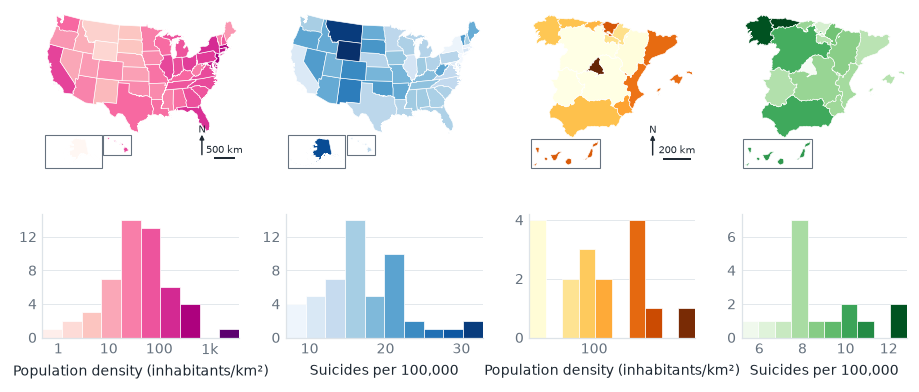

saved: figures\fig1_maps_and_distributions.pdf / .png


In [22]:
def figure1():
    real = {c: MAPS[c]["real"] for c in COUNTRIES}
    frames = {c: inset_frames(real[c], INSETS[c]) for c in COUNTRIES}        # frames of the displaced regions
    asp = {}
    for c in COUNTRIES:
        x0, x1, y0, y1 = map_extent(real[c], frames[c]); asp[c] = (x1 - x0) / (y1 - y0)
    cols = [("United States", "density"), ("United States", "rate"), ("Spain", "density"), ("Spain", "rate")]
    gap, lm, rm = 0.36, 0.40, 0.05                                      # gap between columns leaves room for the y-axis of the histograms
    avail = FULL_W - lm - rm - 3 * gap
    ratios = np.array([asp[c] for c, _ in cols]); widths = avail * ratios / ratios.sum()
    h_map, h_hist, top, mid, bot = widths[0] / ratios[0], 0.95, 0.52, 0.34, 0.50
    H = top + h_map + mid + h_hist + bot
    fig = plt.figure(figsize=(FULL_W, H))
    density_edges = {c: np.geomspace(TAB[c]["density"].min(), TAB[c]["density"].max(), 11) for c in COUNTRIES}
    rate_edges = {c: np.linspace(TAB[c]["rate"].min(), TAB[c]["rate"].max(), 11) for c in COUNTRIES}
    x = lm
    for (c, var), w in zip(cols, widths):
        t = TAB[c]
        vals = t[var]                                                   # "density" or "rate"
        cmap = plt.get_cmap(CMAP_SERIES[(c, var)])
        norm = NORM_FIG1[(c, var)]
        colors = {REGION_CODE[c][region]: cmap(norm(value)) for region, value in zip(t.index, vals)}
        ax = fig.add_axes([x / FULL_W, (bot + h_hist + mid) / H, w / FULL_W, h_map / H])
        draw_regions(ax, real[c], colors); draw_inset_frames(ax, frames[c]); set_map_limits(ax, real[c], frames=frames[c])
        if var == "density": scale_bar(ax, real[c], 500 if c == "United States" else 200)
        axh = fig.add_axes([x / FULL_W, bot / H, w / FULL_W, h_hist / H])
        bins = density_edges[c] if var == "density" else rate_edges[c]
        colored_hist(axh, vals.values, bins, cmap, norm, log=(var == "density"))
        if var == "density":
            axh.xaxis.set_major_formatter(FuncFormatter(pop_formatter)); axh.xaxis.set_minor_locator(NullLocator())
            axh.set_xlabel("Population density (inhabitants/km²)")
        else:
            axh.set_xlabel("Suicides per 100,000")
        x += w + gap
    return fig

fig = figure1()
plt.show()
save_figure(fig, "fig1_maps_and_distributions")

## 13. Figure 2 — Density and rate: area cartograms next to the correlation

### 13.1 Colour scales of Figure 2

*What it does.* Defines `NORM_FIG2`, the normalisation of the suicide rate in Figure 2: a **linear** scale that starts at **0** and ends at the **maximum rate of each country**. Starting at zero keeps the visual weight honest (a rate twice as high looks twice as dark), and each country has its own maximum because the two countries differ in level, so the two colour bars do not share a numerical range. The colormaps come from `CMAP_BOTH` in the central palette (darker = higher rate in both countries).

In [23]:
NORM_FIG2 = {c: Normalize(vmin=0, vmax=float(TAB[c]["rate"].max())) for c in COUNTRIES}

### 13.2 Figure 2

*What it shows.* **Left (cartograms):** every region is deformed so that its **area is proportional to its population**, and coloured by its suicide rate. Regions with many inhabitants grow and regions with few shrink; because the factor of growth is the density of the region relative to the national average, dense regions swell and sparse regions shrink. **Right (scatter):** the same regions as points, with population density (logarithmic scale) against suicide rate, the fitted line, Spearman's ρ with its bootstrap interval, and R² of the fitted line.

*Design choices.* The same four regions are marked with the **same numbers** in the cartogram and in the scatter (they are named in the caption). The square under each cartogram is the **area legend**; the displaced regions (Alaska, Hawaii, Canary Islands) are enclosed in a frame. Circles (US) and squares (Spain) repeat the country code of the other figures. Each country has its own colour bar, starting at 0 (see 13.1).

*What the cell does.* Draws both cartograms with the colour scale of 13.1, adds numbered badges at the highlighted regions (`HIGHLIGHT`), draws the scatter plots, the line, the badges and the statistics (`STAT["density"]`, section 10.1), and returns the figure; the call below shows it and saves it.

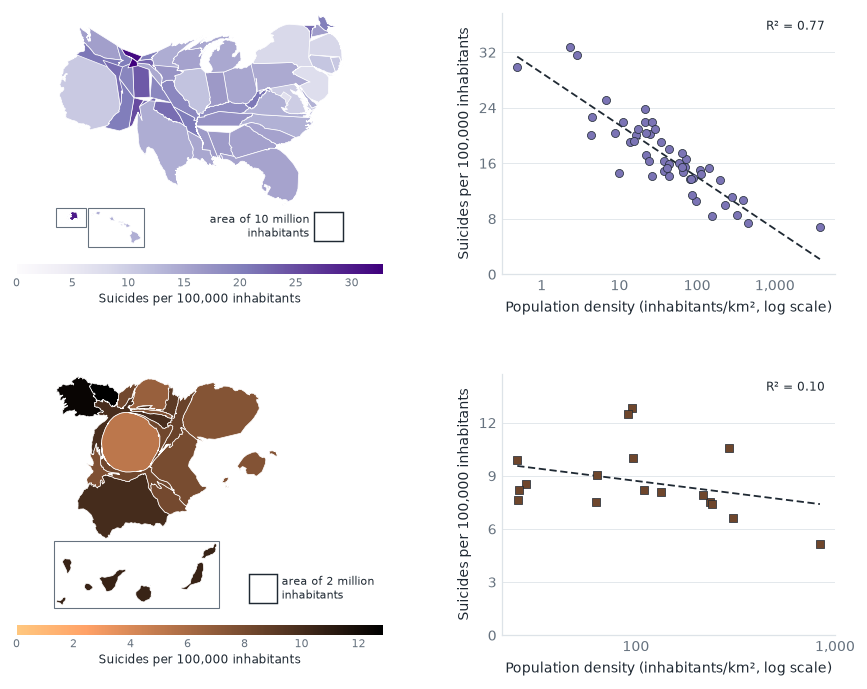

saved: figures\fig2_cartogram_and_correlation.pdf / .png


In [24]:
HIGHLIGHT = {                                    # regions numbered in the cartogram and the scatter (see the caption)
    "United States": ["California", "Texas", "New York", "Wyoming"],
    "Spain": ["Andalucía", "Comunidad de Madrid", "Castilla y León", "Principado de Asturias"],
}

def figure2():
    fig = plt.figure(figsize=(FULL_W, 5.7))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.45, 1], left=0.035, right=0.985, top=0.94, bottom=0.10, wspace=0.15, hspace=0.38)

    for row, c in enumerate(COUNTRIES):
        t, m = TAB[c], MAPS[c]
        geoms = m["carto"]
        cmap = plt.get_cmap(CMAP_BOTH[c])

        # ---- cartogram: area = population, colour = suicide rate
        ax_map = fig.add_subplot(gs[row, 0])
        colors = {REGION_CODE[c][region]: cmap(NORM_FIG2[c](value)) for region, value in zip(t.index, t["rate"])}
        draw_regions(ax_map, geoms, colors, lw=0.4)
        frames = inset_frames(geoms, INSETS[c])                                # frames of the displaced regions
        draw_inset_frames(ax_map, frames)
        set_map_limits(ax_map, geoms, frames=frames)
        ax_map.set_anchor("W")

        # for n, r in enumerate(HIGHLIGHT[c], start=1):                       # numbered regions
        #     number_badge(ax_map, anchor_point(geoms[REGION_CODE[c][r]]), n)

        x0, x1, y0, y1 = geom_bbox(geoms)                                    # area legend: a square of key_pop inhabitants
        side = np.sqrt(m["k"] * m["key_pop"])
        ax_map.add_patch(Rectangle((x1 - side, y0 + 0.01 * (y1 - y0)), side, side, fc="none", ec=INK, lw=0.8))
        label_y = y0 + 0.01 * (y1 - y0) + side / 2
        if c == "Spain":                                                     # the label goes to the right of the square
            ax_map.text(x1 + 0.02 * (x1 - x0), label_y, f"area of {m['key_pop']/1e6:g} million\ninhabitants",
                        ha="left", va="center", fontsize=6, color=INK)
            ax_map.set_xlim(ax_map.get_xlim()[0], x1 + 0.32 * (x1 - x0))
        else:                                                                # ... or to the left of it
            ax_map.text(x1 - side - 0.015 * (x1 - x0), label_y, f"area of {m['key_pop']/1e6:g} million\ninhabitants",
                        ha="right", va="center", fontsize=6, color=INK)

        cb = fig.colorbar(ScalarMappable(norm=NORM_FIG2[c], cmap=cmap), ax=ax_map, orientation="horizontal",
                          fraction=0.04, pad=0.055, aspect=35)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, labelsize=6, pad=2)
        cb.set_label("Suicides per 100,000 inhabitants", fontsize=6.5, labelpad=2)

        # ---- scatter: population density vs suicide rate
        ax = fig.add_subplot(gs[row, 1])
        x, y = t["density"], t["rate"]
        s = STAT["density"][c]
        xs = np.geomspace(x.min(), x.max(), 100)
        ax.plot(xs, s["intercept"] + s["slope"] * np.log10(xs), color=INK, lw=1.0, ls=(0, (4, 2)), zorder=2)
        ax.scatter(x, y, s=20, marker=COUNTRY_MARKER[c], color=cmap(0.65), edgecolors=INK, linewidths=0.4, zorder=3)

        # for n, region in enumerate(HIGHLIGHT[c], start=1):                   # highlighted regions and their numbers
        #     x_region, y_region = t.loc[region, "density"], t.loc[region, "rate"]
        #     ax.scatter([x_region], [y_region], s=25, marker=COUNTRY_MARKER[c], color=cmap(0.65), edgecolors=INK, linewidths=1.0, zorder=4)
        #     ax.annotate(str(n), (x_region, y_region), xytext=(6, 6), textcoords="offset points", ha="center", va="center",
        #                 fontsize=6, fontweight="bold", bbox=dict(boxstyle="circle,pad=0.18", fc="white", ec=INK, lw=0.7), zorder=10)

        ax.set_xscale("log")
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, pos: f"{v:,.0f}"))
        ax.set_ylim(0, t["rate"].max() * 1.15)
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
        ax.set_xlabel("Population density (inhabitants/km², log scale)")
        ax.set_ylabel("Suicides per 100,000 inhabitants")
        clean_axes(ax, "y")

        # ax.text(0.97, 0.97,
        #         f"Spearman ρ = {s['rho']:+.2f}\nR² = {s['r2']:.2f}\n95% CI [{s['ci'][0]:+.2f}, {s['ci'][1]:+.2f}]",
        #         transform=ax.transAxes, ha="right", va="top", fontsize=6.5, linespacing=1.4,
        #         bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))

        ax.text(0.97, 0.97,
            f"R² = {s['r2']:.2f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=6.5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))

    return fig

fig = figure2()
plt.show()
save_figure(fig, "fig2_cartogram_and_correlation")

## 14. Figure 3 — National evolution: population and suicide rate since 2001

*What it shows.* For each country, the **percentage change since 2001** of the national population (dashed) and of the national suicide rate (solid). The neutral grey area between both lines is the distance between them: how far the rate moved away from population growth. The end labels give the final change.

*Design choices.* The four colours are the four identities of the central palette (`COLOR_SERIES`): population pink (US) and red (Spain), suicide rate blue (US) and green (Spain). **Line style carries the same information as colour**: dashed = population, solid = suicide rate. The legend therefore lists the four lines explicitly, each with its own colour and style. Both panels share the vertical axis so the countries can be compared.

*What the cell does.* Computes shared y-limits from both countries, draws the two lines, the shaded gap, the 2001 reference and the end labels of each panel, builds the four-item legend and returns the figure; the call below shows it and saves it. Note that this figure is 12 in wide, not 7.1 in: if it is scaled to the page width its text will be smaller than in the other figures.

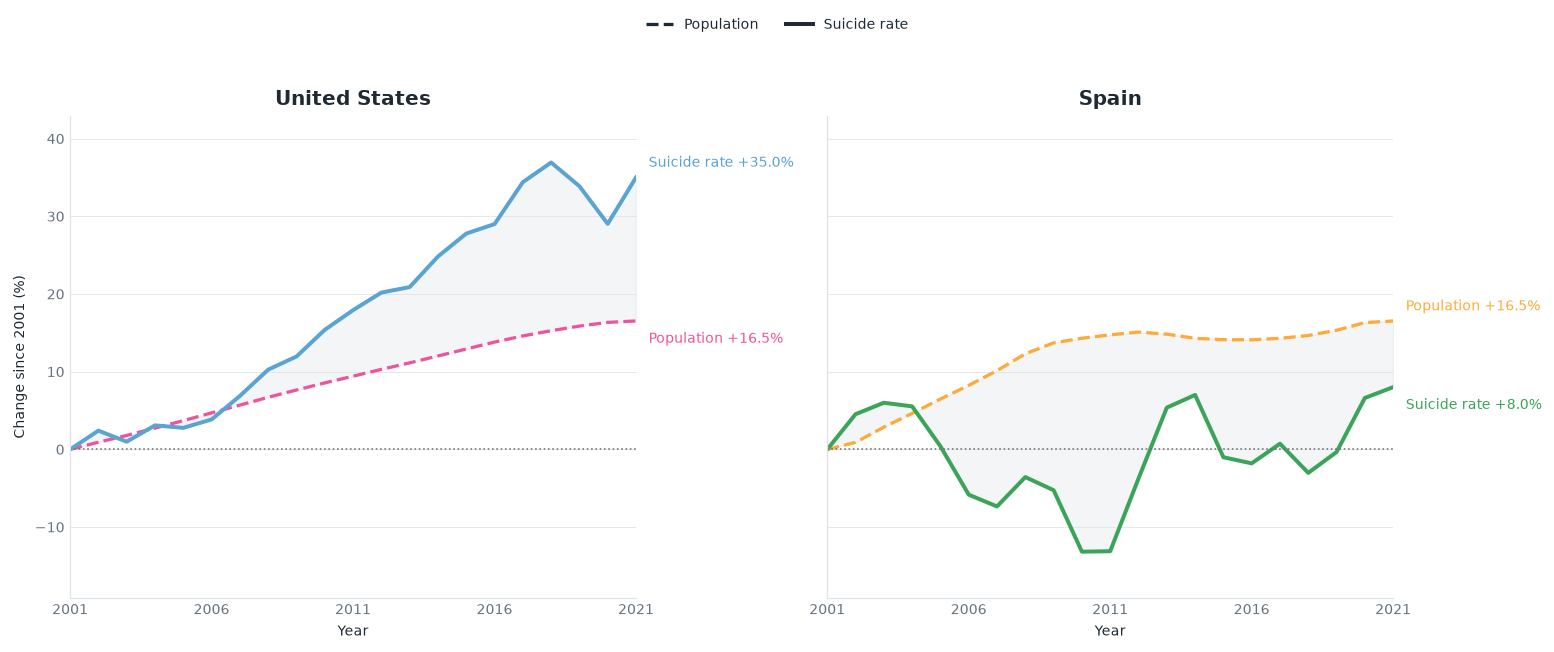

saved: figures\figure3_national_evolution.pdf / .png


In [25]:
def figure3():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

    all_values = []                                                    # shared y-axis limits
    for c in COUNTRIES:
        all_values.extend(national[c]["pop_change"].values)
        all_values.extend(national[c]["rate_change"].values)
    ymin, ymax = min(all_values), max(all_values)
    padding = (ymax - ymin) * 0.12
    ymin -= padding
    ymax += padding

    for ax, c in zip(axes, COUNTRIES):
        n = national[c]
        x = n.index.values
        pop, rate = n["pop_change"].values, n["rate_change"].values
        pop_color, rate_color = COLOR_SERIES[(c, "density")], COLOR_SERIES[(c, "rate")]
        rate_on_top = np.mean(rate) > np.mean(pop)

        ax.plot(x, pop, color=pop_color, linestyle="--", linewidth=1.8, label="Population")        # population: dashed
        ax.plot(x, rate, color=rate_color, linestyle="-", linewidth=2.2, label="Suicide rate")     # suicide rate: solid
        ax.fill_between(x, pop, rate, color=LIGHT, alpha=0.35)                                     # neutral gap
        ax.axhline(0, color="0.45", linewidth=0.9, linestyle=":")                                  # reference: 2001

        ax.annotate(f"Population {pop[-1]:+.1f}%", xy=(x[-1], pop[-1]), xytext=(7, -10 if rate_on_top else 8),
                    textcoords="offset points", fontsize=8, color=pop_color, va="center")
        ax.annotate(f"Suicide rate {rate[-1]:+.1f}%", xy=(x[-1], rate[-1]), xytext=(7, 8 if rate_on_top else -10),
                    textcoords="offset points", fontsize=8, color=rate_color, va="center")

        ax.set_title(c, fontsize=11, fontweight="bold")
        ax.set_xlim(2001, 2021)
        ax.set_ylim(ymin, ymax)
        ax.set_xticks(np.arange(2001, 2022, 5))
        ax.set_xlabel("Year")
        clean_axes(ax)

    axes[0].set_ylabel("Change since 2001 (%)")

    legend_handles = [
        Line2D([], [], color=INK, linestyle="--", linewidth=1.8, label="Population"),
        Line2D([], [], color=INK, linestyle="-", linewidth=2.2, label="Suicide rate"),
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=2,
        frameon=False
    )
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    return fig

fig = figure3()
plt.show()
save_figure(fig, "figure3_national_evolution")

## 15. Figure 4 — Regional evolution: heatmaps and trajectories

### 15.1 Data of the heatmaps

*What it does.* For each country, builds a table with **one row per region and one column per year** with the suicide rate (`HEATMAP_DATA`). Regions are ordered from the highest to the lowest mean rate over the whole period, so the ordering is a property of the data and not of the chosen year.

In [26]:
HEATMAP_DATA = {}
for c in COUNTRIES:
    p = PANELS[c]
    region_order = p.groupby("region")["rate"].mean().sort_values(ascending=False).index     # highest mean rate first
    HEATMAP_DATA[c] = p.pivot(index="region", columns="year", values="rate").reindex(region_order)

### 15.2 Figure 4

*What it shows.* **Top:** heatmaps of the suicide rate by region (rows) and year (columns) for each country; regions are ordered by mean rate and each country has its own colour scale starting at 0 (the palettes are those of Fig. 1, `CMAP_SERIES`). **Bottom:** the same data as **trajectories**: one thin line per region, the **median** of the regions in each year (thick line with markers) and the band between the 25th and 75th percentiles. The dotted vertical line marks the year used in Figures 1 and 2.

*Design choices.* The two bottom panels have **independent vertical axes** (each runs from 0 to 110 % of the highest rate of its country), because the countries differ in level and a shared axis would flatten the Spanish trajectories. They use the colours of the relationship figure (`RELATIONSHIP_COLOR`) and the country markers.

*What the cell does.* Draws the two heatmaps with their colour bars and the two trajectory panels, with a legend for the median, the individual regions and the interquartile band, and returns the figure; the call below shows it and saves it.

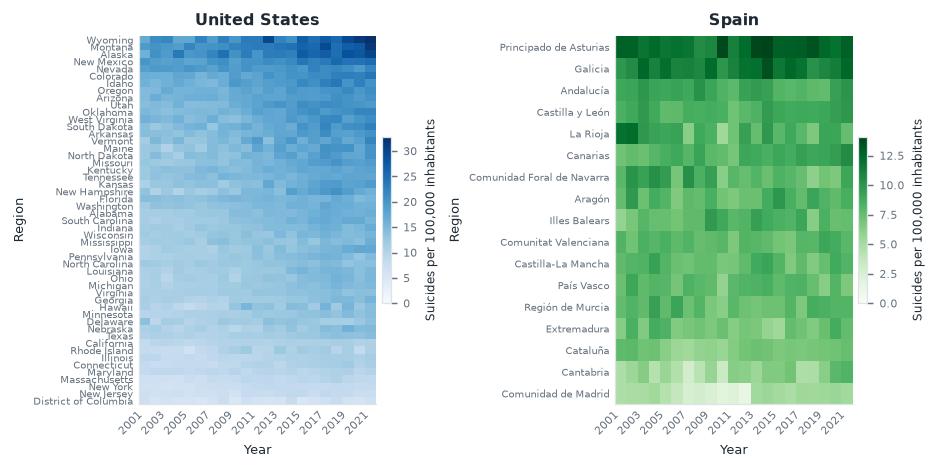

saved: figures\figure4_regional_evolution.pdf / .png


In [27]:
def figure4():
    # fig, axes = plt.subplots(2, 2, figsize=(FULL_W, 6.5), constrained_layout=True)
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 3.5), constrained_layout=True)
    # ---- 1. heatmaps of the suicide rate (palettes of Figure 1, independent scales)
    for col, c in enumerate(COUNTRIES):
        # ax = axes[0, col]
        ax = axes[col]
        data = HEATMAP_DATA[c]
        im = ax.imshow(data.values, aspect="auto", cmap=CMAP_SERIES[(c, "rate")], vmin=0, vmax=float(data.max().max()),
                       interpolation="nearest")
        ax.set_title(c, fontsize=9, fontweight="bold")
        ax.set_yticks(np.arange(len(data.index)))
        ax.set_yticklabels(data.index, fontsize=5.5)
        tick_positions = np.arange(0, len(data.columns), 2)                # one label every two years
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(data.columns[tick_positions], rotation=45, ha="right", fontsize=6)
        ax.set_xlabel("Year", fontsize=7)
        ax.set_ylabel("Region", fontsize=7)
        cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.025)
        cbar.set_label("Suicides per 100,000 inhabitants", fontsize=6.5)
        cbar.ax.tick_params(labelsize=6)
        clean_axes(ax, grid=None)

    # ---- 2. regional trajectories (independent y-axis for each country)
    # for col, c in enumerate(COUNTRIES):
    #     ax = axes[1, col]
    #     p = PANELS[c]
    #     color = RELATIONSHIP_COLOR[c]

    #     for region, g in p.groupby("region"):                              # one thin line per region
    #         g = g.sort_values("year")
    #         ax.plot(g["year"], g["rate"], color=color, alpha=0.20, linewidth=0.65, zorder=1)

    #     annual = (p.groupby("year")["rate"]                                # distribution of the regions in every year
    #               .agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
    #               .sort_index())
    #     years = annual.index.to_numpy()

    #     ax.fill_between(years, annual["q25"].to_numpy(), annual["q75"].to_numpy(), color=color, alpha=0.16, linewidth=0, zorder=2)
    #     ax.plot(years, annual["median"].to_numpy(), color=color, linewidth=2.2, marker=COUNTRY_MARKER[c], markersize=3,
    #             markeredgecolor="white", markeredgewidth=0.5, zorder=3, label="Regional median")
    #     ax.axvline(YEAR, color=MUTED, linewidth=0.8, linestyle=":", zorder=0)           # year of Figures 1 and 2

    #     # ax.set_title(c, fontsize=9, fontweight="bold")
    #     ax.set_xlim(2001, 2021)
    #     ax.set_ylim(0, p["rate"].max() * 1.10)
    #     ax.set_xticks(np.arange(2001, 2022, 5))
    #     ax.set_xlabel("Year", fontsize=7)
    #     ax.set_ylabel("Suicides per 100,000 inhabitants", fontsize=7)
    #     ax.tick_params(labelsize=6.5)
    #     clean_axes(ax)

    #     ax.plot([], [], color=color, alpha=0.25, linewidth=0.8, label="Individual regions")        # legend proxies
    #     ax.fill_between([], [], [], color=color, alpha=0.16, label="25th–75th percentile")
    #     ax.legend(frameon=False, fontsize=6, loc="upper left")
    return fig

fig = figure4()
plt.show()
save_figure(fig, "figure4_regional_evolution")

**Suggested caption — Figure 4.** *Regional evolution of the crude suicide rate, 2001–2021, in the United States (50 states and DC) and Spain (17 autonomous communities). Top: heatmaps of the rate by region (rows, ordered from the highest to the lowest mean rate) and year (columns); each country has its own colour scale starting at 0. Bottom: trajectory of every region (thin lines), median of the regions in each year (thick line with markers) and interquartile range (band). The vertical dotted line marks 2021, the year shown in Figures 1 and 2. The two bottom panels have independent vertical axes.*

## 16. Supplementary figure

### Figure S1 — Funnel plot: are regional differences larger than chance?

*What it shows.* Suicide rate against population for each region of `YEAR`, with the range of rates expected **from chance alone** (Poisson variation) around the national rate: the dark band is the 95 % range and the light band the 99.8 % range. A region outside the light band (black diamond) differs from the national rate more than chance would explain. Small regions are allowed to deviate more because they have few suicides, so the bands narrow as population grows.

*Why a supplement.* It supports the narrative (differences between regions are real, not only small-number noise) without being one of the main messages. Shapes (circles and squares for regions, black diamonds for the outliers) carry the information, so it also works in greyscale. Colours are those of the relationship figure (`RELATIONSHIP_COLOR`).

*What the cell does.* `funnel_limits` gives the limits (Wilson–Hilferty approximation of the Poisson quantiles) for a region of a given population; `funnel_outside` flags the regions beyond the 99.8 % limits (`FUNNEL_OUT`, also used in section 18); the rest draws both countries and returns the figure.

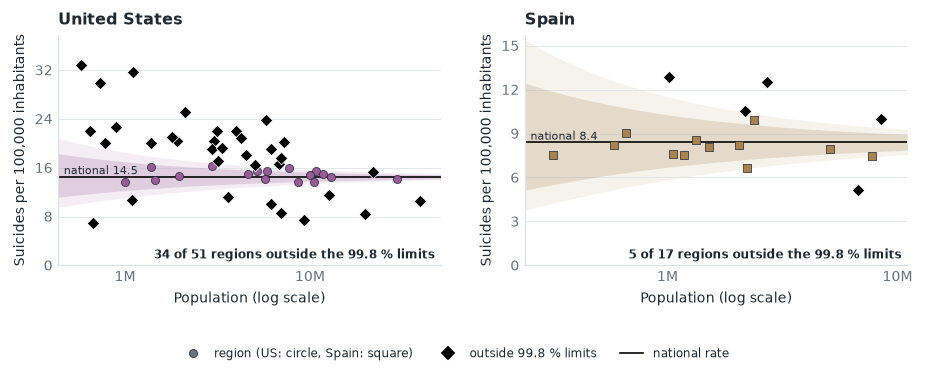

saved: figures\figS1_funnel.pdf / .png


In [28]:
def funnel_limits(pop, p0, n_years, z):
    # Wilson-Hilferty approximation to the Poisson limits for a rate per 100,000 (p0 = national rate)
    lam = np.maximum(p0 * np.asarray(pop) * n_years / 100_000, 1e-9)         # expected number of suicides
    return p0 * np.maximum(1 - 1 / (9 * lam) + z / (3 * np.sqrt(lam)), 0) ** 3

def funnel_outside(t, p0, n_years, z=3.09):
    up, dn = funnel_limits(t["population"], p0, n_years, z), funnel_limits(t["population"], p0, n_years, -z)
    return (t["rate"] > up) | (t["rate"] < dn)

FUNNEL_OUT = {c: funnel_outside(t, NATIONAL_RATE_YEAR[c], 1) for c, t in TAB.items()}

def figureS1():
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, 2.9))
    for ax, c in zip(axes, COUNTRIES):
        t, p0, col, out = TAB[c], NATIONAL_RATE_YEAR[c], RELATIONSHIP_COLOR[c], FUNNEL_OUT[c]
        xs = np.geomspace(t["population"].min() * 0.75, t["population"].max() * 1.3, 250)
        ax.set_xscale("log")
        ax.fill_between(xs, funnel_limits(xs, p0, 1, -3.09), funnel_limits(xs, p0, 1, 3.09), color=col, alpha=0.10, lw=0, zorder=0)
        ax.fill_between(xs, funnel_limits(xs, p0, 1, -1.96), funnel_limits(xs, p0, 1, 1.96), color=col, alpha=0.22, lw=0, zorder=1)
        ax.axhline(p0, color="black", lw=0.9, zorder=2)
        ax.scatter(t.loc[~out, "population"], t.loc[~out, "rate"], s=20, marker=COUNTRY_MARKER[c], color=col, edgecolors=INK, linewidths=0.4, zorder=4)
        ax.scatter(t.loc[out, "population"], t.loc[out, "rate"], s=24, marker="D", color="black", edgecolors="white", linewidths=0.4, zorder=5)
        ax.set_xlim(xs[0], xs[-1]); ax.set_ylim(0, max(t["rate"].max() * 1.15, funnel_limits(xs[0], p0, 1, 3.09) * 1.02))
        ax.xaxis.set_major_formatter(FuncFormatter(pop_formatter)); ax.xaxis.set_minor_locator(NullLocator())
        ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.set_xlabel("Population (log scale)"); ax.set_ylabel("Suicides per 100,000 inhabitants")
        ax.text(0.985, 0.03, f"{int(out.sum())} of {len(t)} regions outside the 99.8 % limits", transform=ax.transAxes, ha="right", fontsize=6.5, fontweight="bold")
        ax.text(0.015, p0, f"national {p0:.1f}", transform=ax.get_yaxis_transform(), va="bottom", fontsize=6.2)
        ax.set_title(c, loc="left", fontsize=9, fontweight="bold")
        clean_axes(ax, "y")
    key = [Line2D([], [], marker="o", ls="", color=MUTED, mec=INK, mew=0.4, ms=4.5, label="region (US: circle, Spain: square)"),
           Line2D([], [], marker="D", ls="", color="black", ms=4.5, label="outside 99.8 % limits"),
           Line2D([], [], color="black", lw=0.9, label="national rate")]
    fig.legend(handles=key, loc="lower center", ncol=3, frameon=False, fontsize=6.5, bbox_to_anchor=(0.5, -0.01))
    fig.subplots_adjust(left=0.07, right=0.99, top=0.88, bottom=0.27, wspace=0.22)
    return fig

fig = figureS1()
plt.show()
save_figure(fig, "figS1_funnel")

# Experimental Figures

### Figures that are still being tested—optional additions to expand the written work

saved: figures\fig5_radial_density_rate.pdf / .png


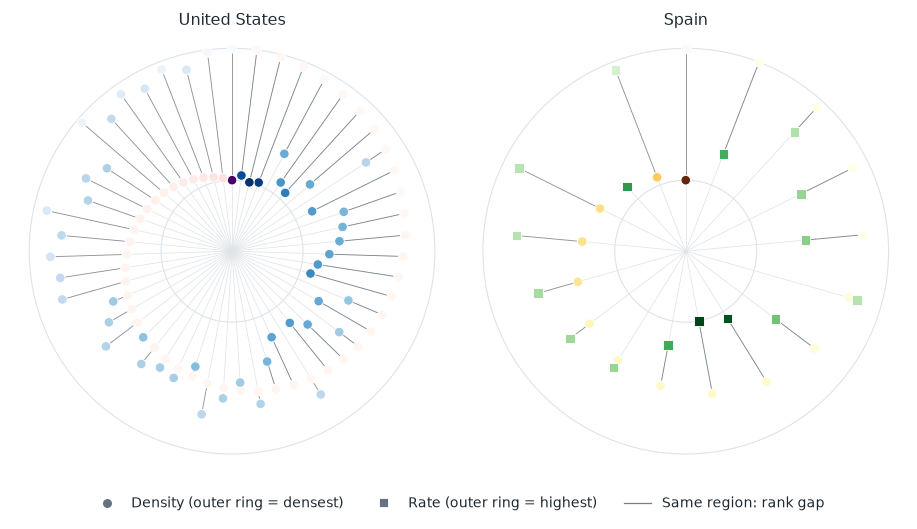

In [29]:
# ============================================================
# Figure 5 — Radial "dumbbell" (non-conventional view of Fig. 2)
# Each spoke = one region, sorted by density (outer ring = density rank,
# inner ring = suicide-rate rank). The gap between the two dots is the
# rank discrepancy between density and rate for that region.
# ============================================================

def radial_dumbbell(country, year=YEAR, ax=None):
    t = TAB[country].copy().sort_values("density", ascending=False)
    n = len(t)
    theta = np.linspace(0, 2 * np.pi, n, endpoint=False) + np.pi / 2  # start at 12 o'clock

    # ranks 1..n (1 = highest density / highest rate) mapped to radii
    rho_density = rankdata(-t["density"].values)          # 1 = densest
    rho_rate    = rankdata(-t["rate"].values)             # 1 = highest rate
    # radius: inner = best rank (smaller), outer = worst rank (larger)
    r_in, r_out = 0.35, 1.0
    radius = lambda rk: r_in + (rk - 1) / (n - 1) * (r_out - r_in)

    rd = radius(rho_density)
    rr = radius(rho_rate)

    xd, yd = rd * np.cos(theta), rd * np.sin(theta)
    xr, yr = rr * np.cos(theta), rr * np.sin(theta)

    if ax is None:
        fig, ax = plt.subplots(figsize=(FULL_W * 0.55, FULL_W * 0.55), subplot_kw=dict(polar=False))

    # spokes: thin grey line from centre to outer ring
    for x, y in zip(rd * np.cos(theta), rd * np.sin(theta)):
        ax.plot([0, x], [0, y], color=LIGHT, lw=0.4, zorder=1)

    # connect the two ranks of the same region
    for i in range(n):
        ax.plot([xd[i], xr[i]], [yd[i], yr[i]], color=INK, lw=0.5, alpha=0.5, zorder=2)

    # density dot (outer ring colour = CMAP_BOTH of density? use CMAP_SERIES)
    cmap_d = plt.get_cmap(CMAP_SERIES[(country, "density")])
    cmap_r = plt.get_cmap(CMAP_SERIES[(country, "rate")])
    norm_d = Normalize(vmin=t["density"].min(), vmax=t["density"].max())
    norm_r = Normalize(vmin=t["rate"].min(),    vmax=t["rate"].max())

    ax.scatter(xd, yd, s=28, c=[cmap_d(norm_d(v)) for v in t["density"].values],
               edgecolor="white", lw=0.5, zorder=3, label="Population density")
    ax.scatter(xr, yr, s=28, c=[cmap_r(norm_r(v)) for v in t["rate"].values],
               edgecolor="white", lw=0.5, marker=COUNTRY_MARKER[country], zorder=3,
               label="Suicide rate")

    # reference circles
    for rr_ in (r_in, r_out):
        circ = plt.Circle((0, 0), rr_, fill=False, ec=LIGHT, lw=0.6, zorder=0)
        ax.add_patch(circ)

    ax.set_xlim(-1.08, 1.08); ax.set_ylim(-1.08, 1.08)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{country} — density vs. suicide-rate rank (2021)", fontsize=9, pad=6)
    return ax


def figure5_radial():
    fig, axes = plt.subplots(1, 2, figsize=(FULL_W, FULL_W * 0.55))
    for ax, c in zip(axes, COUNTRIES):
        radial_dumbbell(c, ax=ax)
        ax.set_title(c, fontsize=9, pad=4)

    # shared legend
    handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor=MUTED, markeredgecolor="white",
               markersize=6, label="Density (outer ring = densest)"),
        Line2D([0], [0], marker=COUNTRY_MARKER["Spain"], color="none", markerfacecolor=MUTED,
               markeredgecolor="white", markersize=6, label="Rate (outer ring = highest)"),
        Line2D([0], [0], color=INK, lw=0.7, alpha=0.6, label="Same region: rank gap"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, -0.01), fontsize=7.5)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    save_figure(fig, "fig5_radial_density_rate")
    return fig


fig5 = figure5_radial()

**Suggested caption — Figure S1.** *Funnel plot of regional suicide rates in 2021 for the United States and Spain. The dark and light bands are the 95 % and 99.8 % ranges expected from Poisson variation around the national rate given each region's population. Black diamonds are regions outside the 99.8 % limits.*

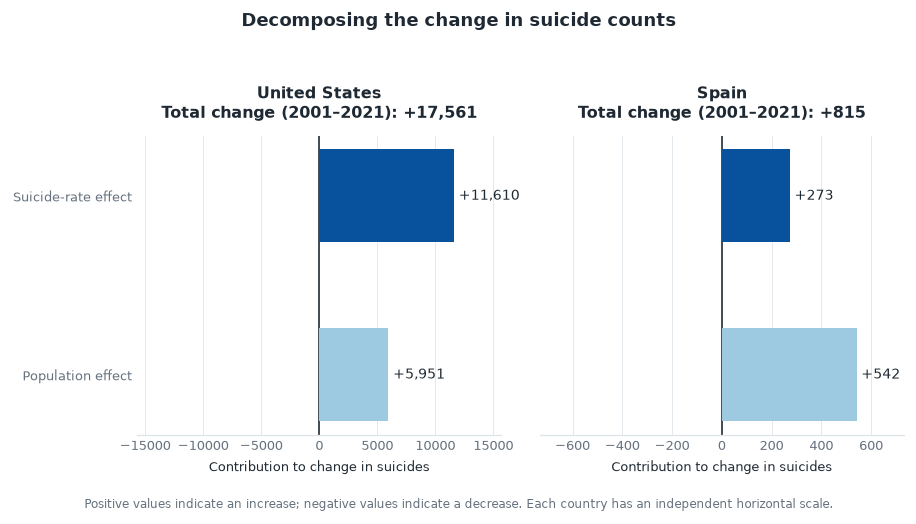

saved: figures\figure6_decomposition.pdf / .png


In [30]:

def figure6():
    # --------------------------------------------------
    # 1. Decompose the change in suicide counts
    # --------------------------------------------------
    decomposition = {}

    for c in COUNTRIES:
        n = national[c].sort_index()

        year0, year1 = n.index[0], n.index[-1]

        P0, P1 = n.loc[year0, "population"], n.loc[year1, "population"]
        R0, R1 = n.loc[year0, "rate"], n.loc[year1, "rate"]
        D0, D1 = n.loc[year0, "suicides"], n.loc[year1, "suicides"]

        # Symmetric decomposition
        population_effect = (P1 - P0) * (R0 + R1) / (2 * 100_000)
        rate_effect = (R1 - R0) * (P0 + P1) / (2 * 100_000)

        total_change = D1 - D0

        assert np.isclose(
            population_effect + rate_effect,
            total_change
        ), f"Decomposition does not add up for {c}"

        decomposition[c] = {
            "population": population_effect,
            "rate": rate_effect,
            "total": total_change,
            "year0": year0,
            "year1": year1,
            "D0": D0,
            "D1": D1,
        }

    # --------------------------------------------------
    # 2. Plot
    # --------------------------------------------------
    fig, axes = plt.subplots(
        1, 2,
        figsize=(FULL_W, 3.5),
        sharex=False,
        sharey=True
    )

    components = ["Population effect", "Suicide-rate effect"]

    colors = {
        "Population effect": "#9ECAE1",
        "Suicide-rate effect": "#08519C",
    }

    for i, (ax, c) in enumerate(zip(axes, COUNTRIES)):
        d = decomposition[c]

        values = [d["population"], d["rate"]]
        y = np.arange(2)

        bars = ax.barh(
            y,
            values,
            height=0.52,
            color=[colors[k] for k in components],
            edgecolor="none",
            zorder=3
        )

        # Independent scale for each country
        max_abs_country = max(abs(v) for v in values)
        ax.set_xlim(
            -max_abs_country * 1.35,
            max_abs_country * 1.35
        )

        ax.axvline(0, color=INK, linewidth=0.9, zorder=2)

        # Value labels
        offset = max_abs_country * 0.035

        for bar, value in zip(bars, values):
            ax.text(
                value + (offset if value >= 0 else -offset),
                bar.get_y() + bar.get_height() / 2,
                f"{value:+,.0f}",
                ha="left" if value >= 0 else "right",
                va="center",
                fontsize=8,
                color=INK
            )

        # Show component labels only on the left panel
        ax.set_yticks(y)

        if i == 0:
            ax.set_yticklabels(components, fontsize=7)
        else:
            ax.tick_params(axis="y", left=False, labelleft=False)

        ax.invert_yaxis()

        # Country and observed total change
        ax.set_title(
            f"{c}\n"
            f"Total change ({d['year0']}–{d['year1']}): "
            f"{d['total']:+,.0f}",
            fontsize=9,
            fontweight="bold",
            pad=10
        )

        ax.set_xlabel("Contribution to change in suicides", fontsize=7)
        ax.tick_params(axis="x", labelsize=7)

        clean_axes(ax, grid="x", left=False)

    # --------------------------------------------------
    # 3. Final layout
    # --------------------------------------------------
    fig.suptitle(
        "Decomposing the change in suicide counts",
        fontsize=10,
        fontweight="bold",
        y=1.05
    )

    fig.text(
        0.5, -0.04,
        "Positive values indicate an increase; negative values indicate a decrease. "
        "Each country has an independent horizontal scale.",
        ha="center",
        fontsize=6.5,
        color=MUTED
    )

    fig.tight_layout()
    return fig


fig = figure6()
plt.show()
save_figure(fig, "figure6_decomposition")


## 17. Accessibility check (colour-vision deficiencies and greyscale)

*What it does.* The course guidelines ask for figures that work for people with colour-vision deficiencies and in black and white. For each **main** figure this cell renders the figure, simulates **deuteranopia** and **protanopia** (Machado et al., 2009, severity 1.0, computed in linear RGB) and converts it to **greyscale** (luminance), and shows the four versions side by side. The check images are saved in `figures/checks/`. They are a quality-control tool and are not part of the paper.

*How the figure is rendered.* `render_rgb` draws the figure on a **new Agg canvas**. This works with any Matplotlib backend: after `plt.show()` the notebook's inline backend replaces the figure canvas by one that cannot render, which is why `fig.canvas.get_renderer()` fails when the check is run after the figures have been displayed.

*How to use it.* Look for: (i) series that become indistinguishable (the same grey), (ii) colour bars that stop being monotonic, (iii) information carried only by hue. Where colours are similar (e.g. red and green lines in the same panel of Fig. 3), the line style (dashed/solid) and the direct labels have to carry the information.

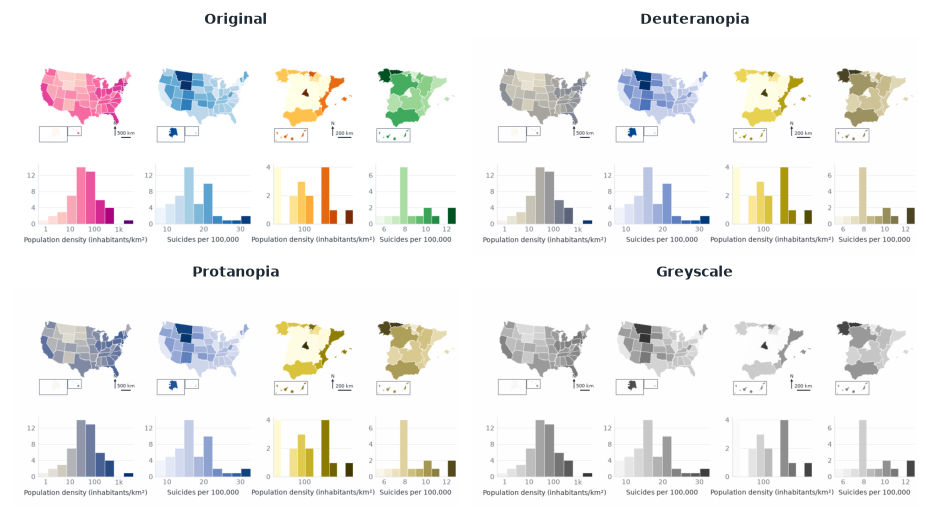

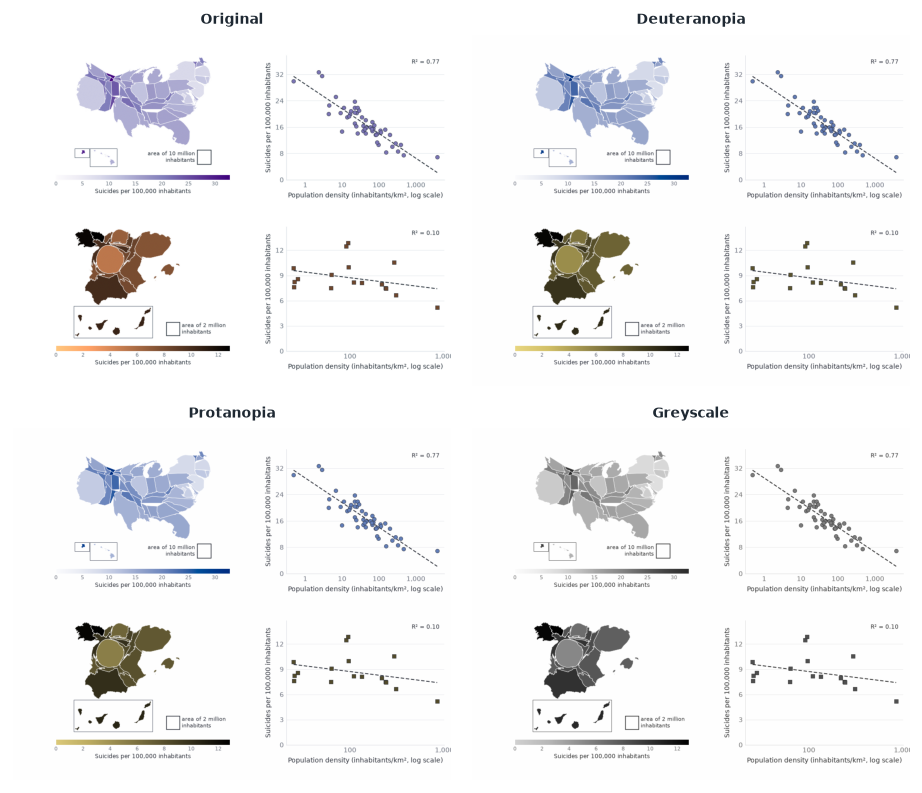

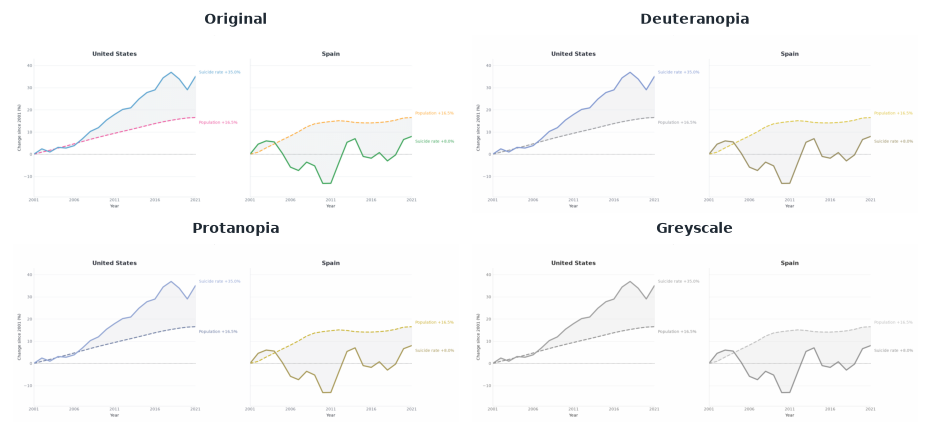

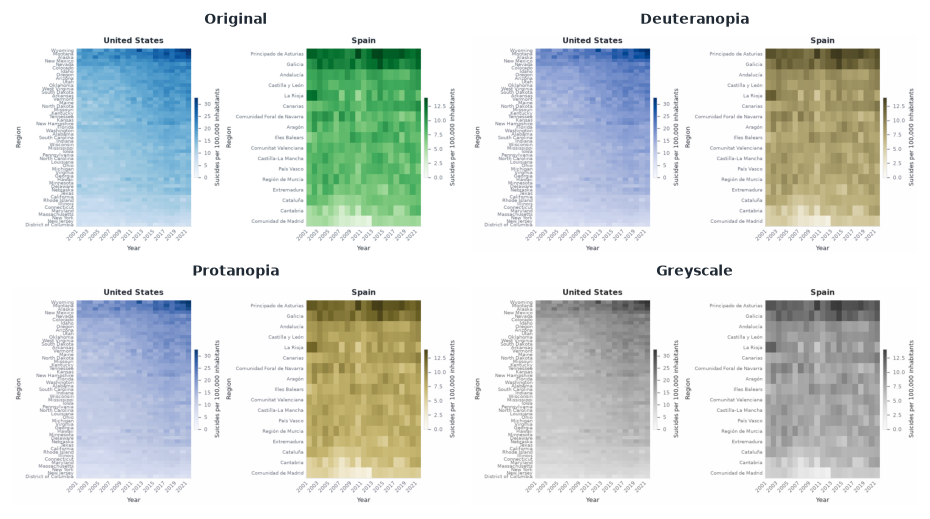

In [31]:
CVD = {
    "Deuteranopia": np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
    "Protanopia":   np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
}
to_linear = lambda c: np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
to_srgb = lambda c: np.where(c <= 0.0031308, c * 12.92, 1.055 * np.clip(c, 0, None) ** (1 / 2.4) - 0.055)

def simulate_cvd(img, kind):
    return np.clip(to_srgb(np.clip(to_linear(img) @ CVD[kind].T, 0, 1)), 0, 1)

def to_greyscale(img):
    y = to_srgb(to_linear(img) @ np.array([0.2126, 0.7152, 0.0722]))
    return np.stack([y, y, y], axis=-1)

def render_rgb(fig):
    canvas = FigureCanvasAgg(fig)                  # a fresh Agg canvas renders the figure with any backend
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[..., :3].astype(float) / 255

def accessibility_check(name, fig):
    img = render_rgb(fig)
    views = [("Original", img), ("Deuteranopia", simulate_cvd(img, "Deuteranopia")),
             ("Protanopia", simulate_cvd(img, "Protanopia")), ("Greyscale", to_greyscale(img))]
    h, w = img.shape[:2]
    qa = plt.figure(figsize=(FULL_W, FULL_W * h / w + 0.4))
    for k, (title, im) in enumerate(views):
        ax = qa.add_subplot(2, 2, k + 1); ax.imshow(im); ax.axis("off"); ax.set_title(title, fontsize=8, fontweight="bold")
    qa.subplots_adjust(left=0.01, right=0.99, top=0.95, bottom=0.01, wspace=0.03, hspace=0.12)
    if SAVE_FIGURES:
        (FIG_DIR / "checks").mkdir(exist_ok=True)
        qa.savefig(FIG_DIR / "checks" / f"{name}_accessibility.png", dpi=150)
    return qa

MAIN_FIGURES = ["fig1_maps_and_distributions", "fig2_cartogram_and_correlation",
                "figure3_national_evolution", "figure4_regional_evolution"]
for name in MAIN_FIGURES:
    qa = accessibility_check(name, FIGS[name])
    plt.show()

## 18. Numbers quoted in the paper

*What it does.* Collects, in one table, every number the text of the paper needs, and writes it to `results/key_numbers.csv`, so the text and the figures always come from the same computation and can be re-checked by anyone who clones the repository. The rows are:

- **Data of `YEAR`:** population, suicides, national rate, number of regions, concentration of the population (share of the 5 most populous regions), medians and ranges of density and rate, highest and lowest regions (support for Fig. 1).
- **Association (Fig. 2):** Spearman ρ between **density** and rate with its bootstrap interval and p-value, R² and slope of the fitted line; for comparison, ρ between **population size** and rate.
- **Sensitivity analysis:** the density correlation **with Ceuta and Melilla** (Spain) and **without DC** (United States), to show how much the main result depends on those regions (section 4).
- **Cartogram accuracy** (mean and maximum area error).
- **National evolution (Fig. 3):** change of the rate and of the population since 2001.
- **Year-by-year correlation (section 10.3):** minimum and maximum ρ and the number of years in which its interval excludes 0.
- **Funnel plot (Fig. S1):** regions outside the 99.8 % limits.

In [32]:
rows = []
def add(country, quantity, value):
    rows.append({"country": country, "quantity": quantity, "value": value})

for c in COUNTRIES:
    t, nat, m = TAB[c], national[c], MAPS[c]
    d, s = STAT["density"][c], STAT["population"][c]
    ry = RHO_YEAR[RHO_YEAR["country"] == c]
    top5 = t["population"].nlargest(5)
    label, sens = SENSITIVITY[c]
    all_pop = TAB_ALL[c]["population"].sum()

    # data of the chosen year
    add(c, f"Population {YEAR} (millions)", round(t["population"].sum() / 1e6, 2))
    add(c, f"Suicides {YEAR}", int(t["suicides"].sum()))
    add(c, f"National crude rate {YEAR} (per 100,000)", round(NATIONAL_RATE_YEAR[c], 2))
    add(c, "Regions analysed", len(t))
    add(c, "Population of excluded regions (% of national)", round((all_pop - t["population"].sum()) / all_pop * 100, 2))
    add(c, "Share of population in the 5 most populous regions (%)", round(top5.sum() / t["population"].sum() * 100, 1))
    add(c, "Five most populous regions", ", ".join(top5.index))
    add(c, "Median regional density (inhabitants/km2)", round(t["density"].median(), 1))
    add(c, "Highest regional density", f"{t['density'].idxmax()} ({t['density'].max():,.0f})")
    add(c, "Lowest regional density", f"{t['density'].idxmin()} ({t['density'].min():,.1f})")
    add(c, "Median regional rate (per 100,000)", round(t["rate"].median(), 2))
    add(c, "Regional rate, 25th-75th percentile", f"{t['rate'].quantile(.25):.1f} - {t['rate'].quantile(.75):.1f}")
    add(c, "Highest regional rate", f"{t['rate'].idxmax()} ({t['rate'].max():.1f})")
    add(c, "Lowest regional rate", f"{t['rate'].idxmin()} ({t['rate'].min():.1f})")

    # association (Fig. 2)
    add(c, f"Spearman rho, density vs rate, {YEAR}", round(d["rho"], 2))
    add(c, "Spearman rho (density), bootstrap 95% CI", f"[{d['ci'][0]:.2f}, {d['ci'][1]:.2f}]")
    add(c, "Spearman p-value (density)", float(f"{d['p']:.3g}"))
    add(c, "R2 of the fit rate ~ log10(density)", round(d["r2"], 2))
    add(c, "Fit: change in rate per x10 density", round(d["slope"], 2))
    add(c, f"Spearman rho, population size vs rate, {YEAR}", round(s["rho"], 2))
    add(c, "Spearman rho (population size), bootstrap 95% CI", f"[{s['ci'][0]:.2f}, {s['ci'][1]:.2f}]")
    add(c, "Sensitivity: Spearman rho (density) and 95% CI", f"{sens['rho']:+.2f} [{sens['ci'][0]:+.2f}, {sens['ci'][1]:+.2f}] ({label})")

    # cartogram, national evolution, yearly correlation, funnel
    add(c, "Cartogram area error, mean / max (%)", f"{m['mean_err']*100:.1f} / {m['max_err']*100:.1f}")
    add(c, "National crude rate first -> last year (per 100,000)", f"{nat['rate'].iloc[0]:.2f} -> {nat['rate'].iloc[-1]:.2f}")
    add(c, "Change of the rate since the first year (%)", round(nat["rate_change"].iloc[-1], 1))
    add(c, "Change of the population since the first year (%)", round(nat["pop_change"].iloc[-1], 1))
    add(c, "Annual rho (density): minimum", round(ry["rho"].min(), 2))
    add(c, "Annual rho (density): maximum", round(ry["rho"].max(), 2))
    add(c, "Years with annual-rho interval excluding 0", f"{int(((ry['lo'] > 0) | (ry['hi'] < 0)).sum())} of {len(ry)}")
    add(c, f"Regions outside 99.8% funnel limits, {YEAR}", int(FUNNEL_OUT[c].sum()))

KEY_NUMBERS = pd.DataFrame(rows)
KEY_NUMBERS.to_csv(RESULTS_DIR / "key_numbers.csv", index=False)
display(KEY_NUMBERS.pivot(index="quantity", columns="country", values="value").loc[KEY_NUMBERS["quantity"].drop_duplicates()])
print("saved:", (RESULTS_DIR / "key_numbers.csv").relative_to(REPO_ROOT))

country,Spain,United States
quantity,,
Population 2021 (millions),47.23,332.1
Suicides 2021,3964,48183
"National crude rate 2021 (per 100,000)",8.39,14.51
Regions analysed,17,51
Population of excluded regions (% of national),0.36,0.0
Share of population in the 5 most populous regions (%),65.1,37.2
Five most populous regions,"Andalucía, Cataluña, Comunidad de Madrid, Comu...","California, Texas, Florida, New York, Pennsylv..."
Median regional density (inhabitants/km2),96.9,40.6
Highest regional density,Comunidad de Madrid (840),"District of Columbia (3,802)"


saved: results\key_numbers.csv


## 19. From figures to text: skeleton of the Results section

Each paragraph rests on one figure and on rows of `results/key_numbers.csv`; fill in the numbers from there.

- **3.1 The data (Fig. 1).** Describe the two variables separately in each country. Density: how spread it is (use the median and the highest and lowest regions, and the share of the population in the 5 most populous regions). Suicide rate: the median, the 25th–75th percentile and the highest and lowest regions; compare the two countries *with their histograms*, not with the colours (each map has its own scale). State that the maps show one year and why.
- **3.2 Density and rate (Fig. 2).** Explain the cartogram in one sentence (area ∝ population, so dense regions swell and sparse regions shrink). Say what colour the swollen regions have in each country (use the numbered regions), then give Spearman's ρ with its interval and the R² for each country. Say explicitly if an interval includes 0 (no clear association). Mention the sensitivity analysis (with/without Ceuta and Melilla; without DC).
- **3.3 National evolution (Fig. 3).** Compare the change of the national rate with that of the population since 2001 in each country, and say whether the gap between them grows or shrinks.
- **3.4 Regional evolution (Fig. 4).** Describe which regions keep the highest and lowest rates (heatmaps), whether the spread between regions changes over time (bands) and how the median compares with the individual regions. Say in how many years the annual correlation interval excludes 0 (section 10.3) to show whether 2021 is typical.
- **Supplement (Fig. S1).** How many regions differ from the national rate by more than chance.

## 20. Interpretation, limitations and reproducibility checklist

**Limitations to state in the paper (self-reflection).**
- Rates are **crude** (not age-adjusted), so differences in age structure between regions and countries are not removed.
- The associations are **ecological** (about regions, not individuals) and **descriptive**, not causal. Population density summarises urbanisation, income, age and many other regional characteristics that are not modelled.
- Ceuta and Melilla are **excluded** (section 4); the sensitivity analysis of section 18 shows what changes if they are included. DC is included, and its effect is also shown.
- Densities are computed from simplified boundaries, so they differ slightly from official figures.
- One year (`YEAR`) is shown in the maps; small regions have few suicides in a single year, so their rates are noisy. Section 10.3 checks the other years.
- Spain has only 17 regional units, so its estimates are imprecise (wide intervals).
- The cartogram deforms shapes: areas are accurate (see the reported error) but shapes and distances are not. Enclaves and insets are rescaled, not deformed. Alaska, Hawaii and the Canary Islands are insets (enclosed in frames in the maps) that are not in their geographic position and not to scale.
- Every map and histogram of Fig. 1 and every cartogram of Fig. 2 has its own colour scale; colours must not be compared between countries.

**Reproducibility checklist.**
- [x] All paths built with `pathlib` from the repository root found at run time; none is machine-specific.
- [x] Boundaries joined to the data by **region code**, with assertions on both sides; the excluded regions are defined in one place (`EXCLUDED_REGIONS`).
- [x] All colours defined in one place (section 7.1).
- [x] After the one-time preparation of section 8.3, only `numpy`, `pandas`, `matplotlib` and `scipy` are needed (no internet, no `geopandas`); versions are printed at the top.
- [x] Fixed random seed for the bootstrap; deterministic cartogram.
- [x] Sanity checks on the data fail loudly if the files change; the cartogram reports its accuracy.
- [x] Every number in the text is written to `results/key_numbers.csv`; every figure to `figures/` as PDF (vector, editable text) and 300-dpi PNG.
- [x] Figures tested for colour-vision deficiencies and greyscale (section 17).